# Notebook 03 — PatchCore

## 1. Motivation and hypotheses
Reconstruction models can copy defects and blur normal structure. PatchCore
instead compares local pretrained features against a memory of normal patches.
Hypothesis: local nearest-neighbor distances separate fitting-derived synthetic
edits from normal appearance without a learned reconstruction objective.
This first execution is a live small normal-only CUDA pilot; development and
all-category confirmation remain pending. Earlier notebooks/results are preserved.

## 2. Architecture and mathematics
For frozen CNN activations $F_2(x),F_3(x)$, apply local average pooling and align
the coarser map to the finer grid. Concatenation gives $z_{h,w}\in\mathbb R^{384}$.
The fitting-normal memory is $M=\{z_i\}$. A coreset approximately minimizes
$\max_{z\in M}\min_{m\in M_C}\|Pz-Pm\|_2$, using random projection $P$ and greedy
farthest-first traversal of a capped candidate pool. Search uses original
384-dimensional vectors: $a_{h,w}=\min_{m\in M_C}\|z_{h,w}-m\|_2$.
Continuous patch distances are interpolated into a pixel map. Image scores use
maximum patch distance or a fixed top-1% mean; they are not pixel probabilities.

This is a **simplified PatchCore variant**, not paper equivalence: ResNet18,
direct concatenation, capped candidate-pool projected coreset, no neighborhood
image-score reweighting and initially no Gaussian smoothing. Sources:
[Roth et al., CVPR 2022](https://arxiv.org/abs/2106.08265) and
[torchvision weights](https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.resnet18).


In [1]:
from pathlib import Path
import sys,json,time,copy,traceback,subprocess,math
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
import numpy as np,pandas as pd,matplotlib.pyplot as plt,torch,psutil
from anomaly_detection.data import CATEGORIES,sha256
from anomaly_detection.basic_cnn import seed_everything,synthetic_batch
from anomaly_detection.cnn_research import read_partition,require_fitting,load_resized
from anomaly_detection.tracking import record,config_hash
from anomaly_detection.patchcore_research import Resources
torch.set_num_threads(4)
assert torch.cuda.is_available()
seed_everything(2026)
torch.backends.cuda.matmul.allow_tf32=False
print(torch.__version__,torch.cuda.get_device_name(0))
print('GPU GiB:',torch.cuda.get_device_properties(0).total_memory/2**30)
print('RAM GiB:',psutil.virtual_memory().total/2**30)


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


2.11.0+cu128 NVIDIA GeForce RTX 4060 Laptop GPU
GPU GiB: 7.99560546875
RAM GiB: 31.70067596435547


## 3. Dataset and frozen partition verification
The existing loader checks manifest hashes and normal-only provenance. No
official test image or mask is accessed by this pilot. The first 24 fitting
normals form the pilot bank; first eight development normals measure transfer.
## 4. Environment and GPU verification
Use the existing locked CUDA environment. Both ResNet18 and WideResNet50-2
weights are cached; start with the smaller ResNet18 and download neither.
Actual shapes, resources and correctness are measured below. Weight hashes and
the source/environment identities are recorded before fitting.


In [2]:
fit_rows=read_partition('fit','bottle').iloc[:24].copy()
require_fitting(fit_rows)
dev_rows=read_partition('development','bottle').iloc[:8].copy()
print('Pilot fitting normals:',len(fit_rows),'development normals:',len(dev_rows))
metadata=json.loads((ROOT/'reports/dataset_validation.json').read_text())
print(json.dumps(metadata['partitions'],indent=2))


Pilot fitting normals: 24 development normals: 8
{
  "fit": {
    "path": "reports/partitions/seed2026-fit.csv",
    "sha256": "f0549001ec7bbf124b67cb3979d2af64f593a2b5c9f420838f539938b4ade912",
    "images": 2551
  },
  "development": {
    "path": "reports/partitions/seed2026-development.csv",
    "sha256": "e1e49dee7d8111b50409e49ab51a046d6888b3a4f82256a927c6b16ace33a4df",
    "images": 539
  },
  "calibration": {
    "path": "reports/partitions/seed2026-calibration.csv",
    "sha256": "dc46dd58419fc0dd32e20f174efe4e208df49bc25c65bdb06afe2dbd1a418ff6",
    "images": 539
  },
  "test": {
    "path": "reports/partitions/seed2026-test.csv",
    "sha256": "bf873b574776e11d2931d3c9004a2570a5362303f10206f0d2afa271274dcfa2",
    "images": 1725
  }
}


## 5. Preprocessing
Default ResNet18 classification weights resize the short edge to 256 and center
crop 224. For full-image localization, retain the previous models' PIL bilinear
256-square geometry, then call the official weight transform with resize/crop
256. This documented geometry override keeps all borders and official ImageNet
mean/std; it does not use test statistics. Aspect ratios can be distorted.
## 6. Pretrained extraction
All parameters and BatchNorm statistics are frozen, including after `.train()`.
## 7. Layer selection
At 256 square: layer1 is 64x64x64, layer2 is 128x32x32 and layer3 is 256x16x16.
Layer2+layer3 yields 1,024 patches/image; using layer1 would quadruple patch
count and search cost. The initial pair balances detail and semantic context.
## 8. Multi-scale aggregation
Pool 3x3 locally, align by bilinear interpolation and concatenate channels.
## 9. Patch embeddings
Flatten spatial locations, not channels: B,C,H,W → (BHW),C.
## 10. Normal memory
Only category-specific fitting normals supply bank vectors.
## 11. Coreset
Random candidate cap 20,000; Gaussian projection to 32 dimensions; greedy
farthest-first selection. Keep original full-dimensional vectors for scoring.
## 12. Nearest-neighbor search
GPU blocked exhaustive L2, at most 512x2048 temporary distances (4 MiB).
Direct subtraction refines selected distances. Index choices near numerical ties
remain float32-precision limited. This is an efficient PyTorch flat-search
equivalent, avoiding an additional FAISS installation on this Windows environment.
## 13. Pixel maps
Interpolate continuous distances; masks are never bilinearly transformed.
## 14. Image scores
Compare max-patch and top-1%-patch mean on permitted development evidence.
The following is the actual implementation, executed as definitions here.


In [3]:
"""Bounded ResNet18 PatchCore variant, not a paper-equivalent reproduction."""
import math
import hashlib
from pathlib import Path
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.models import resnet18, ResNet18_Weights


class PatchExtractor(nn.Module):
    """Frozen layer2/layer3 features; whole-image geometry preserves edge defects.

    Official V1 mean/std and torchvision weight transforms are used, with a
    documented crop-size override: inputs are already whole-image 256 squares,
    then resize/crop 256 (identity geometry). Default classification 224 center
    cropping is deliberately avoided. No learned test/normal statistics.
    """
    def __init__(self, pretrained=True):
        super().__init__()
        weights=ResNet18_Weights.IMAGENET1K_V1
        if pretrained:
            path=Path(torch.hub.get_dir())/'checkpoints'/Path(weights.url).name
            if not path.is_file():
                raise FileNotFoundError('Register a weight acquisition before downloading: '+str(path))
            self.weight_sha256=hashlib.sha256(path.read_bytes()).hexdigest()
            if not self.weight_sha256.startswith(path.stem.split('-')[-1]):
                raise ValueError('Cached ImageNet weight hash does not match torchvision identity')
        else:self.weight_sha256='untrained-test-only'
        network=resnet18(weights=weights if pretrained else None)
        self.stem=nn.Sequential(network.conv1,network.bn1,network.relu,network.maxpool)
        self.layer1=network.layer1
        self.layer2=network.layer2
        self.layer3=network.layer3
        self.transform=weights.transforms(crop_size=256,resize_size=256,antialias=True)
        self.requires_grad_(False)
        self.eval()

    def train(self,mode=True):
        # Even parent .train() must not update ImageNet BatchNorm statistics.
        return super().train(False)

    @torch.inference_mode()
    def feature_maps(self,images):
        if images.ndim!=4 or images.shape[1:]!=(3,256,256) or not images.is_floating_point():
            raise ValueError('Expected B,3,256,256 float RGB in [0,1]')
        x=self.transform(images)
        first=self.layer1(self.stem(x))
        second=self.layer2(first)
        third=self.layer3(second)
        return first,second,third

    @torch.inference_mode()
    def forward(self,images):
        _,second,third=self.feature_maps(images)
        return align_features(second,third)


def align_features(shallow,deep):
    """3x3 local average pooling, coarse bilinear alignment, channel concatenation."""
    if shallow.ndim!=4 or deep.ndim!=4 or shallow.shape[0]!=deep.shape[0]:
        raise ValueError('Matching B,C,H,W feature batches required')
    local=F.avg_pool2d(shallow,3,1,1)
    coarse=F.avg_pool2d(deep,3,1,1)
    coarse=F.interpolate(coarse,size=local.shape[-2:],mode='bilinear',align_corners=False)
    return torch.cat([local,coarse],dim=1)


def patch_embeddings(features):
    if features.ndim!=4:raise ValueError('Expected B,C,H,W features')
    return features.permute(0,2,3,1).reshape(-1,features.shape[1]).contiguous()


@torch.inference_mode()
def projected_coreset(embeddings,budget,seed=2026,candidate_limit=20000,projection_dim=32):
    """Random capped candidate pool -> projected farthest-first traversal.

    Returns unique indices into original embeddings plus measured projected
    coverage distances. Search uses original full-dimensional vectors, not the
    projection. The cap is a disclosed approximation to a full-data coreset.
    """
    if embeddings.ndim!=2 or not torch.isfinite(embeddings).all():raise ValueError('Finite N,D matrix required')
    n,d=embeddings.shape
    if not 1<=budget<=min(n,candidate_limit) or projection_dim<1:raise ValueError('Invalid coreset budget')
    generator=torch.Generator().manual_seed(seed)
    candidates=torch.randperm(n,generator=generator)[:candidate_limit].to(embeddings.device)
    projection=torch.randn(d,projection_dim,generator=generator).to(embeddings.device)/math.sqrt(projection_dim)
    reduced=embeddings[candidates].float()@projection
    distances=torch.full((len(candidates),),float('inf'),device=embeddings.device)
    available=torch.ones(len(candidates),dtype=torch.bool,device=embeddings.device)
    chosen=[]
    current=0  # randomized candidate order supplies a seeded initial center
    for _ in range(budget):
        chosen.append(current)
        available[current]=False
        delta=(reduced-reduced[current]).square().sum(1)
        distances=torch.minimum(distances,delta)
        current=int(distances.masked_fill(~available,-1).argmax())
    indices=candidates[torch.tensor(chosen,device=embeddings.device)]
    coverage=dict(candidate_count=len(candidates),projected_radius=float(distances.max().sqrt()),
                  projected_mean_distance=float(distances.sqrt().mean()),projection_dim=projection_dim)
    return indices,coverage


@torch.inference_mode()
def nearest_neighbors(queries,bank,query_chunk=512,bank_chunk=2048):
    """Exhaustive float32 L2 search with a bounded Qchunk x Mchunk matrix.

    GEMM finds the nearest index; direct subtraction refines the selected
    distance, avoiding cancellation in self/near-self distance values. As with
    float32 flat search, almost-tied index choices are numerical-precision limited.
    No Q x M x D tensor or complete image-batch distance matrix is constructed.
    """
    if queries.ndim!=2 or bank.ndim!=2 or queries.shape[1]!=bank.shape[1] or not len(bank):
        raise ValueError('Compatible query and nonempty bank matrices required')
    if query_chunk<1 or bank_chunk<1 or queries.device!=bank.device:raise ValueError('Invalid chunks/device')
    distances=[];indices=[]
    for q in queries.float().split(query_chunk):
        best=torch.full((len(q),),float('inf'),device=q.device)
        best_index=torch.zeros(len(q),dtype=torch.long,device=q.device)
        for start in range(0,len(bank),bank_chunk):
            b=bank[start:start+bank_chunk].float()
            squared=(q.square().sum(1,keepdim=True)+b.square().sum(1)[None]-2*(q@b.T)).clamp_min_(0)
            values,positions=squared.min(1)
            improved=values<best
            best=torch.minimum(best,values)
            best_index=torch.where(improved,positions+start,best_index)
        distances.append((q-bank[best_index]).square().sum(1).sqrt())
        indices.append(best_index)
    return torch.cat(distances),torch.cat(indices)


def pixel_maps(patch_distances,shape=(256,256)):
    if patch_distances.ndim!=3:raise ValueError('Expected B,Hpatch,Wpatch')
    return F.interpolate(patch_distances[:,None],size=shape,mode='bilinear',align_corners=False)[:,0]


def image_scores(patch_distances,aggregation='max'):
    flat=patch_distances.flatten(1)
    if aggregation=='max':return flat.amax(1)
    if aggregation=='top1pct':return flat.topk(max(1,math.ceil(flat.shape[1]*.01)),dim=1).values.mean(1)
    raise ValueError('Expected max or top1pct')


def save_bank(path,bank,indices,category,config,provenance):
    if path.exists():raise FileExistsError(path)
    torch.save(dict(bank=bank.cpu(),indices=indices.cpu(),category=category,config=config,provenance=provenance),path)


def load_bank(path,category,device='cpu'):
    saved=torch.load(path,map_location='cpu',weights_only=True)
    if saved['category']!=category:raise ValueError('Category-specific bank mismatch')
    return saved['bank'].to(device),saved


## 15. Initial verification and measured pilot
Hypothesis: 24 fitting normals and a 512-patch coreset fit safely, exact-search
fixtures agree with float64 reference distances, self-search returns zero and
the score map has the declared shape. These checks precede all-category work.
The pilot is a feasibility experiment, not an official detection benchmark.


In [4]:
identifier='03-pilot-resnet18-bottle-s2026-v1'
config=dict(backbone='resnet18',weights='IMAGENET1K_V1',layers=['layer2','layer3'],
    resolution=256,bank_budget=512,candidate_limit=20000,projection_dim=32,
    query_chunk=512,bank_chunk=2048,seed=2026,normalize=False)
local=ROOT/'outputs/patchcore'/identifier
local.mkdir(parents=True,exist_ok=True)
report=ROOT/'reports/patchcore';report.mkdir(parents=True,exist_ok=True)
entry=dict(experiment_id=identifier+'-start',model_family='PatchCoreVariant',categories=['bottle'],
    hypothesis='A cached frozen ResNet18 with a 512-patch projected coreset supports bounded exact search and finite anomaly maps.',
    preprocessing='Whole PIL RGB bilinear 256 + official V1 transform with identity resize/crop 256 geometry',
    hyperparameters=config,seed=2026,
    environment=dict(torch=torch.__version__,gpu=torch.cuda.get_device_name(0),ram_bytes=psutil.virtual_memory().total,
        git_sha=subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip(),
        source_sha256={p:sha256(ROOT/p) for p in ['src/anomaly_detection/patchcore.py','src/anomaly_detection/patchcore_research.py']},
        lock_sha256=sha256(ROOT/'requirements.lock.txt'),partitions=metadata['partitions']),
    training={},metrics={},calibration={},paths=dict(local=local.relative_to(ROOT).as_posix()),
    interpretation='Reserved before normal-only pilot; no official test access',decision='Measure feasibility before expansion',status='started')
record(ROOT/'experiments',entry)
try:
    extractor=PatchExtractor().cuda()
    print('Weight SHA256:',extractor.weight_sha256)
    print('Transform:',extractor.transform)
    with Resources() as resource:
        fitting=load_resized(fit_rows,256).cuda().float()/255
        development=load_resized(dev_rows,256).cuda().float()/255
        tick=time.perf_counter()
        features=extractor(fitting)
        torch.cuda.synchronize();extraction_seconds=time.perf_counter()-tick
        shapes=[list(f.shape) for f in extractor.feature_maps(fitting[:1])]
        embeddings=patch_embeddings(features)
        tick=time.perf_counter()
        indices,coverage=projected_coreset(embeddings,config['bank_budget'],config['seed'])
        bank=embeddings[indices].clone()
        torch.cuda.synchronize();coreset_seconds=time.perf_counter()-tick
        self_distances,_=nearest_neighbors(bank[:16],bank)
        assert self_distances.eq(0).all()
        g=torch.Generator().manual_seed(3)
        fixture_bank=torch.randn(37,16,generator=g).cuda()
        fixture_query=torch.randn(13,16,generator=g).cuda()
        actual,_=nearest_neighbors(fixture_query,fixture_bank,7,11)
        reference=torch.cdist(fixture_query.double(),fixture_bank.double(),compute_mode='donot_use_mm_for_euclid_dist').min(1).values
        torch.testing.assert_close(actual.double(),reference,rtol=1e-6,atol=1e-6)
        dev_features=extractor(development)
        tick=time.perf_counter()
        distances,_=nearest_neighbors(patch_embeddings(dev_features),bank)
        torch.cuda.synchronize();search_seconds=time.perf_counter()-tick
        patch_maps=distances.reshape(len(development),32,32)
        maps=pixel_maps(patch_maps)
        assert maps.shape==(8,256,256) and torch.isfinite(maps).all() and maps.ge(0).all()
        for _ in range(20):nearest_neighbors(patch_embeddings(dev_features[:1]),bank)
        times=[]
        for _ in range(50):
            tick=time.perf_counter();nearest_neighbors(patch_embeddings(dev_features[:1]),bank)
            torch.cuda.synchronize();times.append((time.perf_counter()-tick)*1000)
        altered=development[:1].clone()
        altered[:,:,96:128,96:128]=1-altered[:,:,96:128,96:128]
        altered_distances,_=nearest_neighbors(patch_embeddings(extractor(altered)),bank)
        altered_map=pixel_maps(altered_distances.reshape(1,32,32))
    fitting_counts={c:len(read_partition('fit',c)) for c in CATEGORIES}
    result=dict(configuration=config,weight_sha256=extractor.weight_sha256,
        weight_url=ResNet18_Weights.IMAGENET1K_V1.url,
        extractor_parameters=sum(p.numel() for p in extractor.parameters()),
        trainable_parameters=sum(p.numel() for p in extractor.parameters() if p.requires_grad),
        feature_shapes=shapes,embedding_shape=list(embeddings.shape),patches_per_image=1024,
        extraction_seconds=extraction_seconds,coreset_seconds=coreset_seconds,
        search_8_images_seconds=search_seconds,search_p50_ms=float(np.median(times)),
        search_p95_ms=float(np.quantile(times,.95)),coverage=coverage,
        resources=resource.result,bank_bytes=bank.numel()*bank.element_size(),
        feature_bytes_per_image=1024*384*4,
        all_category_fitting_images=fitting_counts,
        expected_feature_cache_bytes={c:n*1024*384*4 for c,n in fitting_counts.items()},
        projected_three_seed_final_extraction_seconds=extraction_seconds/24*sum(fitting_counts.values()),
        coreset_cost_caveat='Pilot bank 512; candidate cap and selected bank budget affect final cost. Deterministic extraction runs once, not three times.',
        correctness=dict(float64_fixture=True,zero_self_distances=True,finite_nonnegative_maps=True,map_shape=list(maps.shape)))
    torch.save(dict(bank=bank.cpu(),indices=indices.cpu(),config=config),local/'pilot-bank.pt')
    torch.save(dict(normal=development.cpu(),maps=maps.cpu(),altered=altered.cpu(),altered_map=altered_map.cpu()),local/'pilot-panels.pt')
    with (report/(identifier+'-result.json')).open('x') as stream:json.dump(result,stream,indent=2)
    event=copy.deepcopy(entry)
    event.update(experiment_id=identifier+'-result',status='completed',metrics=result,
        decision='Pilot correctness passed; assess measured workload before bounded development',
        interpretation='Feasibility evidence only; synthetic map example is not a real-defect benchmark.')
    record(ROOT/'experiments',event)
    print(json.dumps(result,indent=2))
except BaseException as exc:
    (local/'failure.txt').write_text(traceback.format_exc(),encoding='utf-8')
    event=copy.deepcopy(entry)
    event.update(experiment_id=identifier+'-failure',status='failed',decision='preserve and investigate',interpretation=str(exc))
    record(ROOT/'experiments',event)
    raise


Weight SHA256: f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec
Transform: ImageClassification(
    crop_size=[256]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


{
  "configuration": {
    "backbone": "resnet18",
    "weights": "IMAGENET1K_V1",
    "layers": [
      "layer2",
      "layer3"
    ],
    "resolution": 256,
    "bank_budget": 512,
    "candidate_limit": 20000,
    "projection_dim": 32,
    "query_chunk": 512,
    "bank_chunk": 2048,
    "seed": 2026,
    "normalize": false
  },
  "weight_sha256": "f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec",
  "weight_url": "https://download.pytorch.org/models/resnet18-f37072fd.pth",
  "extractor_parameters": 2782784,
  "trainable_parameters": 0,
  "feature_shapes": [
    [
      1,
      64,
      64,
      64
    ],
    [
      1,
      128,
      32,
      32
    ],
    [
      1,
      256,
      16,
      16
    ]
  ],
  "embedding_shape": [
    24576,
    384
  ],
  "patches_per_image": 1024,
  "extraction_seconds": 0.442961100001412,
  "coreset_seconds": 0.8132004999970377,
  "search_8_images_seconds": 0.030620199999248143,
  "search_p50_ms": 4.397949998747208,
  "searc

### Pilot interpretation and decision
Use the measured output above to decide feasibility. Self-distance and float64
fixture checks test implementation correctness, not detection quality. Coreset
coverage is measured only in projected candidate space; it does not guarantee
coverage of every original patch. The synthetic edit below is a map sanity check.
Licensed image panels remain local; public outputs retain measurements.


Recorded pilot gate: extraction 0.443 s, coreset 0.813 s, search p50 4.398 ms, allocated VRAM 0.257 GiB, peak sampled RSS 1.555 GiB. Correctness checks passed; the recorded decision was to proceed with bounded development. See [pilot gate](../reports/patchcore/pilot_gate.json), committed before development selection.

In [5]:
fig,axes=plt.subplots(2,2,figsize=(8,8))
limit=float(torch.cat([maps[:1],altered_map]).max())
for i,(images,heatmaps) in enumerate([(development[:1],maps[:1]),(altered,altered_map)]):
    axes[i,0].imshow(images[0].cpu().permute(1,2,0));axes[i,0].axis('off')
    axes[i,1].imshow(heatmaps[0].cpu(),vmin=0,vmax=limit);axes[i,1].axis('off')
axes[0,0].set_title('Real development normal')
axes[1,0].set_title('Synthetic edit, not official defect')
plt.tight_layout();plt.show()


## 16. Development experiments
Predeclared bottle/cable/carpet/tile; bank budgets 256/1024/2048; max versus
top-1%-patch mean. One frozen backbone/layer pair, one blocked search backend.
Normal development diagnostics and explicitly synthetic inner-fitting holdout
probes support selection. All variants, timings and decisions must be retained.
## 17. Candidate selection
Four-category mean (proxy image AUROC + proxy pixel AP)/2, then latency/bank size
for exact ties. No official test-label tuning. Selection is pending.
## 18. Threshold calibration
Reserved normal partition only; image higher q95 and separate pixel q99.5.
Report counts, strict > decisions, test FPR and uncertainty. Pending freeze.
## 19. Frozen configuration
Freeze complete source, weight, coreset, preprocessing, scoring and calibration
identities before confirmation. No freeze or final evaluation is claimed yet.
## 20. All-category evaluation
Pending the measured gate, then all 15 categories, preferably three coreset seeds.
Cache compatible deterministic features instead of extracting them repeatedly.
## 21. Anomaly maps and overlays
Final original/heatmap/overlay/native-ground-truth panels are pending evaluation.
## 22. Failure analysis
Investigate small scratches, texture, structure, memory coverage and threshold
instability using observed data. Do not infer causes from unseen results.
## 23. Runtime and GPU/CPU memory
Pilot measures extraction, coreset, search, RSS sampling and CUDA peaks. Final
latency will use 50 warmups/200 batch-one timed runs, plus separate end-to-end cost.
## 24. Comparison with CNN and Autoencoder
Pending final results. Read exact stored summaries and category-matched scores;
do not substitute rounded references or select a winner on AUROC alone.
## 25. Conclusions and limitations
Only implementation/pilot evidence exists at this chronological point. The
variant omits paper reweighting and smoothing, caps coreset candidates and uses
ImageNet transfer with a localization geometry override. The public notebook
removes only licensed image-panel outputs; the full executed pilot stays local.
No SuperSimpleNet work is part of this milestone.


# Continued chronological record: development and confirmation
The preceding pilot was executed live. The continuation executes analysis of
separately recorded bank-building and official-evaluation jobs. It **does not
claim those jobs ran live in this kernel**. Their actual implementation is
included below as executable function definitions. Pending statements above
describe the historical pilot state; the completed phases below supersede them.
## 16. Development implementation and provenance
Hypothesis: a larger normal coreset improves local coverage enough to justify
its additional storage/search cost. No MVTec gradients update the pretrained CNN.
Thus there are no training-loss/epoch curves; coverage, diagnostics and resource
curves document this nonparametric fit. Deterministic features are cached once.


In [1]:
from pathlib import Path
import sys,json,time,math
ROOT=Path.cwd()
if ROOT.name=='notebooks':ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
import numpy as np,pandas as pd,matplotlib.pyplot as plt,torch
from PIL import Image
from matplotlib.patches import Rectangle
from anomaly_detection.patchcore import PatchExtractor,nearest_neighbors,pixel_maps,image_scores,load_bank
from anomaly_detection.cnn_research import read_partition,inner_fit_split,load_resized,make_probes
from anomaly_detection.data import CATEGORIES,TEXTURES,autodiscover_data_root,sha256
from anomaly_detection.tracking import config_hash
torch.set_num_threads(4);torch.backends.cuda.matmul.allow_tf32=False
report=ROOT/'reports/patchcore'
frozen=json.loads((ROOT/'configs/patchcore_frozen.json').read_text())
summary=json.loads((report/'summary.json').read_text())
print('Frozen weight SHA256:',frozen['weight_sha256'])
print('Cached weight files (availability/size only, not multiple backbone experiments):')
print([(p.name,p.stat().st_size) for p in (Path(torch.hub.get_dir())/'checkpoints').glob('*.pth')])
print('ResNet18 is the measured backbone; WideResNet50-2 was not benchmarked.')
print('CUDA:',torch.cuda.get_device_name(0))
counts=[]
for category in CATEGORIES:
    counts.append(dict(category=category,**{p:len(read_partition(p,category)) for p in ['fit','development','calibration','test']}))
display(pd.DataFrame(counts))


Matplotlib is building the font cache; this may take a moment.


Could not save font_manager cache [Errno 13] Permission denied: 'C:\\Users\\shaik\\.matplotlib\\fontlist-v390.json.matplotlib-lock'


Frozen weight SHA256: f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec
Cached weight files (availability/size only, not multiple backbone experiments):
[('resnet18-f37072fd.pth', 46830571), ('wide_resnet50_2-9ba9bcbe.pth', 275905729)]
ResNet18 is the measured backbone; WideResNet50-2 was not benchmarked.


CUDA: NVIDIA GeForce RTX 4060 Laptop GPU


,category,fit,development,calibration,test
0,bottle,147,31,31,83
1,cable,158,33,33,150
2,capsule,155,32,32,132
3,carpet,196,42,42,117
4,grid,186,39,39,78
5,hazelnut,275,58,58,110
6,leather,173,36,36,124
7,metal_nut,154,33,33,115
8,pill,187,40,40,167
9,screw,224,48,48,160


### Actual cache and bank construction
This is the source used for the recorded jobs. `require_fitting` rejects
non-fitting rows before a memory is built. The inner fitting holdout supplies
fixed synthetic probes during development and never enters that development
bank. Final banks use the complete fitting partition. Feature cache hashes
include original rows, weights, transform policy and extractor source identity.


In [2]:
"""PatchCore provenance, deterministic feature caches and scoped resources."""
import threading,time,os,json
from pathlib import Path
import numpy as np
import psutil
import torch
from anomaly_detection.cnn_research import ROOT,read_partition,require_fitting,load_resized
from anomaly_detection.data import sha256
from anomaly_detection.tracking import config_hash
from anomaly_detection.patchcore import patch_embeddings,nearest_neighbors


class Resources:
    """Sample process RSS at 20 Hz; CUDA peaks use PyTorch's allocator counters."""
    def __enter__(self):
        self.process=psutil.Process(os.getpid())
        self.initial=self.process.memory_info().rss;self.peak=self.initial
        self.done=threading.Event()
        def sample():
            while not self.done.wait(.05):self.peak=max(self.peak,self.process.memory_info().rss)
        self.thread=threading.Thread(target=sample,daemon=True);self.thread.start()
        if torch.cuda.is_available():torch.cuda.synchronize();torch.cuda.reset_peak_memory_stats()
        self.started=time.perf_counter()
        return self

    def __exit__(self,*args):
        if torch.cuda.is_available():torch.cuda.synchronize()
        self.done.set();self.thread.join()
        self.peak=max(self.peak,self.process.memory_info().rss)
        self.result=dict(seconds=time.perf_counter()-self.started,cpu_initial_rss_bytes=self.initial,
            cpu_peak_rss_bytes=self.peak,cpu_peak_increment_bytes=self.peak-self.initial,
            cpu_sampling_seconds=.05,peak_gpu_allocated_bytes=torch.cuda.max_memory_allocated(),
            peak_gpu_reserved_bytes=torch.cuda.max_memory_reserved())


@torch.inference_mode()
def feature_cache(extractor,rows,batch_size=16):
    """Immutable once-completed cache, keyed by exact rows, weights and transform.

    This function can load official test images only when called by the frozen
    evaluator. Memory builders independently require fitting-normal provenance.
    """
    if rows.category.nunique()!=1:raise ValueError('A feature cache belongs to one category')
    identity=dict(records=rows[['path','sha256']].to_dict('records'),
        extractor_source_sha256=sha256(ROOT/'src/anomaly_detection/patchcore.py'),
        weight_sha256=extractor.weight_sha256,preprocessing='whole-PIL-bilinear-256; V1-transform-256-identity-geometry',
        layers=['layer2','layer3'],local_pool=3,alignment='bilinear-align_corners_false',dtype='float32')
    key=config_hash(identity)
    folder=ROOT/'outputs/patchcore/features';folder.mkdir(parents=True,exist_ok=True)
    path=folder/(key+'.npy');meta=folder/(key+'.json')
    if meta.exists():
        saved=json.loads(meta.read_text())
        if not path.exists() or sha256(path)!=saved['sha256']:raise ValueError('Feature cache changed')
        return np.load(path,mmap_mode='r'),dict(saved,cache_hit=True)
    if path.exists():raise FileExistsError('Incomplete cache preserved; register recovery: '+str(path))
    with Resources() as resource:
        images=load_resized(rows,256,allow_test=rows.partition.eq('test').all())
        output=np.lib.format.open_memmap(path,mode='w+',dtype=np.float32,shape=(len(rows),1024,384))
        for start in range(0,len(images),batch_size):
            features=extractor(images[start:start+batch_size].cuda().float()/255)
            output[start:start+len(features)]=patch_embeddings(features).reshape(len(features),1024,384).cpu().numpy()
        output.flush();del output
    saved=dict(identity=identity,sha256=sha256(path),path=path.relative_to(ROOT).as_posix(),
        shape=[len(rows),1024,384],bytes=path.stat().st_size,resources=resource.result)
    with meta.open('x') as stream:json.dump(saved,stream,indent=2)
    return np.load(path,mmap_mode='r'),dict(saved,cache_hit=False)


@torch.inference_mode()
def score_embeddings(features,bank,normalize=False,image_batch=4):
    maps=[]
    for start in range(0,len(features),image_batch):
        block=torch.from_numpy(np.array(features[start:start+image_batch])).cuda().float()
        if normalize:block=torch.nn.functional.normalize(block,dim=-1)
        distances,_=nearest_neighbors(block.reshape(-1,block.shape[-1]),bank)
        maps.append(distances.reshape(len(block),32,32).cpu())
    return torch.cat(maps)


def fitting_embeddings(rows,features):
    require_fitting(rows)
    if rows.category.nunique()!=1 or len(rows)!=len(features):raise ValueError('Category/feature provenance mismatch')
    return torch.from_numpy(np.array(features)).reshape(-1,384).cuda()

"""Auditable category-specific normal banks and bounded development proxies."""
import copy,json,time,traceback,subprocess
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import average_precision_score
from anomaly_detection.patchcore import projected_coreset,nearest_neighbors,pixel_maps,image_scores,save_bank
from anomaly_detection.patchcore_research import ROOT,Resources,feature_cache,score_embeddings,fitting_embeddings
from anomaly_detection.cnn_research import read_partition,inner_fit_split,load_resized,make_probes
from anomaly_detection.data import sha256
from anomaly_detection.tracking import record,config_hash
from anomaly_detection.metrics import binary_metrics,calibrate_normal


@torch.inference_mode()
def proxy_cache(extractor,rows):
    identity=dict(rows=rows[['path','sha256']].to_dict('records'),weight=extractor.weight_sha256,
        core=sha256(ROOT/'src/anomaly_detection/patchcore.py'),synthetic_source=sha256(ROOT/'src/anomaly_detection/basic_cnn.py'),seed=9901)
    key=config_hash(identity)
    folder=ROOT/'outputs/patchcore/proxies';folder.mkdir(parents=True,exist_ok=True)
    path=folder/(key+'.npz');meta=folder/(key+'.json')
    if meta.exists():
        saved=json.loads(meta.read_text())
        if sha256(path)!=saved['sha256']:raise ValueError('Changed synthetic feature cache')
        data=np.load(path,allow_pickle=False)
        return data['features'],data['masks'],dict(saved,cache_hit=True)
    if path.exists():raise FileExistsError('Incomplete proxy cache preserved')
    with Resources() as resources:
        original=load_resized(rows,256).cuda()
        probes,masks=make_probes(original,rows)
        features=torch.cat([extractor(x).permute(0,2,3,1).reshape(len(x),1024,384).cpu()
                            for x in probes.split(16)]).numpy()
        masks=masks[:,0].cpu().numpy().astype(np.uint8)
        np.savez(path,features=features,masks=masks)
    saved=dict(identity=identity,path=path.relative_to(ROOT).as_posix(),sha256=sha256(path),resources=resources.result)
    with meta.open('x') as stream:json.dump(saved,stream,indent=2)
    return features,masks,dict(saved,cache_hit=False)


def build_bank(identifier,category,config,extractor,final=False):
    folder=ROOT/'reports/patchcore/runs';folder.mkdir(parents=True,exist_ok=True)
    local=ROOT/'outputs/patchcore'/identifier;local.mkdir(parents=True,exist_ok=False)
    checkpoint=ROOT/'checkpoints/patchcore'/identifier/'bank.pt'
    checkpoint.parent.mkdir(parents=True,exist_ok=False)
    entry=dict(experiment_id=identifier+'-start',model_family='PatchCoreVariant',categories=[category],
        hypothesis=f"A {config['bank_budget']}-patch projected coreset represents category normals within bounded search cost." if not final else 'Fresh category/seed bank confirms frozen policy without test-driven selection.',
        preprocessing='Whole PIL bilinear 256 + V1 transform resize/crop 256; ImageNet normalization',
        hyperparameters=config,seed=config['seed'],environment=dict(torch=torch.__version__,gpu=torch.cuda.get_device_name(0),
            weight_sha256=extractor.weight_sha256,lock_sha256=sha256(ROOT/'requirements.lock.txt'),
            git_sha=subprocess.check_output(['git','rev-parse','HEAD'],cwd=ROOT,text=True).strip(),
            source_sha256={p:sha256(ROOT/p) for p in ['src/anomaly_detection/patchcore.py','src/anomaly_detection/patchcore_research.py','src/anomaly_detection/patchcore_runs.py']},
            partitions=json.loads((ROOT/'reports/dataset_validation.json').read_text())['partitions']),
        training=dict(phase='final' if final else 'development'),metrics={},calibration={},paths=dict(local=local.relative_to(ROOT).as_posix()),
        interpretation='No calibration/test data in bank construction or development',decision='retain actual results',status='started')
    record(ROOT/'experiments',entry)
    started=time.perf_counter()
    try:
        rows=read_partition('fit',category)
        learning,probe_rows=(rows,None) if final else inner_fit_split(rows)
        features,feature_metadata=feature_cache(extractor,learning)
        cache_original_extraction_seconds=feature_metadata['resources']['seconds']
        with Resources() as resources:
            embeddings=fitting_embeddings(learning,features)
            tick=time.perf_counter()
            indices,coverage=projected_coreset(embeddings,config['bank_budget'],config['seed'],
                config['candidate_limit'],config['projection_dim'])
            bank=embeddings[indices].clone();del embeddings
            torch.cuda.synchronize();selection_seconds=time.perf_counter()-tick
            provenance=dict(partition='fit',source_rows_sha256=config_hash(learning[['path','sha256']].to_dict('records')),
                feature_cache=feature_metadata,weight_sha256=extractor.weight_sha256,phase='final' if final else 'development')
            save_bank(checkpoint,bank,indices,category,config,provenance)
        metrics={};timing={}
        if not final:
            dev,dev_meta=feature_cache(extractor,read_partition('development',category))
            probes,masks,probe_meta=proxy_cache(extractor,probe_rows)
            with Resources() as search_resources:
                tick=time.perf_counter();dev_maps=score_embeddings(dev,bank)
                proxy_maps=score_embeddings(probes,bank)
                torch.cuda.synchronize();search_seconds=time.perf_counter()-tick
                spatial=pixel_maps(proxy_maps).numpy()
                pixel_ap=float(average_precision_score(masks.ravel(),spatial.ravel()))
                labels=masks.reshape(len(masks),-1).any(1).astype(int)
                for aggregation in ['max','top1pct']:
                    scores=image_scores(proxy_maps,aggregation).numpy()
                    threshold=calibrate_normal(image_scores(dev_maps,aggregation).numpy())
                    values=binary_metrics(labels,scores,threshold)
                    metrics[aggregation]=dict(**values,pixel_ap=pixel_ap,objective=(values['auroc']+pixel_ap)/2)
                q=torch.from_numpy(np.array(dev[:1])).cuda().reshape(-1,384)
                for _ in range(5):nearest_neighbors(q,bank)
                durations=[]
                for _ in range(20):
                    tick=time.perf_counter();nearest_neighbors(q,bank);torch.cuda.synchronize()
                    durations.append((time.perf_counter()-tick)*1000)
            timing=dict(development_search_seconds=search_seconds,search_p50_ms=float(np.median(durations)),
                search_p95_ms=float(np.quantile(durations,.95)),resources=search_resources.result,
                normal_development_patch_distance_quantiles=np.quantile(dev_maps.numpy(),[0,.5,.95,1]).tolist(),
                normal_cache=dev_meta,proxy_cache=probe_meta)
            np.savez(local/'development_maps.npz',normal=dev_maps.numpy(),proxy=proxy_maps.numpy(),masks=masks)
        result=dict(experiment_id=identifier,category=category,configuration=config,phase='final' if final else 'development',
            fitting_normals=len(learning),probe_sources=0 if final else len(probe_rows),
            candidate_coverage=coverage,coreset_seconds=selection_seconds,bank_resources=resources.result,
            checkpoint=checkpoint.relative_to(ROOT).as_posix(),checkpoint_sha256=sha256(checkpoint),
            checkpoint_bytes=checkpoint.stat().st_size,bank_vector_bytes=bank.numel()*4,
            feature_cache=feature_metadata,original_extraction_seconds=cache_original_extraction_seconds,
            metrics=metrics,development=timing,wall_seconds=time.perf_counter()-started)
        with (folder/(identifier+'-result.json')).open('x') as stream:json.dump(result,stream,indent=2,allow_nan=False)
        event=copy.deepcopy(entry)
        event.update(experiment_id=identifier+'-result',status='completed',metrics=result,
            decision='await bounded development selection' if not final else 'frozen category bank complete')
        record(ROOT/'experiments',event)
        print(identifier,'completed',round(result['wall_seconds'],2),metrics,flush=True)
        return result
    except BaseException as exc:
        (local/'failure.txt').write_text(traceback.format_exc(),encoding='utf-8')
        event=copy.deepcopy(entry)
        event.update(experiment_id=identifier+'-failure',status='failed',decision='preserve failure',interpretation=str(exc))
        record(ROOT/'experiments',event)
        raise


### Experiment 03-dev-b256-bottle-s2026-v1: hypothesis
A 256-patch coreset balances representative coverage against storage and
NN cost on **bottle**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b256-bottle-s2026-v1-result.json).


In [3]:
r=json.loads((report/'runs/03-dev-b256-bottle-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 256,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,1.0,1.0,1.0,0.034483,0.966667,0.983051,"[[28, 1], [0, 29]]",0.805181,0.902591
top1pct,1.0,1.0,1.0,0.172414,0.852941,0.920635,"[[24, 5], [0, 29]]",0.805181,0.902591


Coverage: {'candidate_count': 20000, 'projected_radius': 1.7618927955627441, 'projected_mean_distance': 1.1509586572647095, 'projection_dim': 32}
Coreset seconds: 0.5448910999984946 search p50 ms: 3.7501499991776654
Normal-development patch distance quantiles: [0.02304319106042385, 1.2479074597358704, 1.6097388863563538, 2.086667776107788]
Fitting cache reused: False


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **1.000000 /
1.000000**; proxy pixel AP:
**0.805181**. Coreset construction took
**0.545 s**. Budget 256: best four-category objective 0.748237; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **reject**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Experiment 03-dev-b256-cable-s2026-v1: hypothesis
A 256-patch coreset balances representative coverage against storage and
NN cost on **cable**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b256-cable-s2026-v1-result.json).


In [4]:
r=json.loads((report/'runs/03-dev-b256-cable-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 256,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,0.901145,0.907937,0.516129,0.032258,0.941176,0.666667,"[[30, 1], [15, 16]]",0.575176,0.73816
top1pct,0.955255,0.960025,0.580645,0.0,1.0,0.734694,"[[31, 0], [13, 18]]",0.575176,0.765215


Coverage: {'candidate_count': 20000, 'projected_radius': 2.7091336250305176, 'projected_mean_distance': 2.0438051223754883, 'projection_dim': 32}
Coreset seconds: 0.21128460000181803 search p50 ms: 3.1409499988512835
Normal-development patch distance quantiles: [1.0521074533462524, 2.0722460746765137, 2.514579093456268, 3.243817090988159]
Fitting cache reused: False


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **0.901145 /
0.955255**; proxy pixel AP:
**0.575176**. Coreset construction took
**0.211 s**. Budget 256: best four-category objective 0.748237; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **reject**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Experiment 03-dev-b256-carpet-s2026-v1: hypothesis
A 256-patch coreset balances representative coverage against storage and
NN cost on **carpet**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b256-carpet-s2026-v1-result.json).


In [5]:
r=json.loads((report/'runs/03-dev-b256-carpet-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 256,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,0.779093,0.850745,0.615385,0.025641,0.96,0.75,"[[38, 1], [15, 24]]",0.545898,0.662495
top1pct,0.794872,0.86038,0.615385,0.0,1.0,0.761905,"[[39, 0], [15, 24]]",0.545898,0.670385


Coverage: {'candidate_count': 20000, 'projected_radius': 1.266541600227356, 'projected_mean_distance': 1.0062733888626099, 'projection_dim': 32}
Coreset seconds: 0.17449330000090413 search p50 ms: 4.240799999024603
Normal-development patch distance quantiles: [0.6748386025428772, 1.0534679293632507, 1.2072280287742616, 1.5536571741104126]
Fitting cache reused: False


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **0.779093 /
0.794872**; proxy pixel AP:
**0.545898**. Coreset construction took
**0.174 s**. Budget 256: best four-category objective 0.748237; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **reject**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Experiment 03-dev-b256-tile-s2026-v1: hypothesis
A 256-patch coreset balances representative coverage against storage and
NN cost on **tile**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b256-tile-s2026-v1-result.json).


In [6]:
r=json.loads((report/'runs/03-dev-b256-tile-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 256,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,0.819336,0.863616,0.53125,0.0,1.0,0.693878,"[[32, 0], [15, 17]]",0.482854,0.651095
top1pct,0.82666,0.868158,0.53125,0.0,1.0,0.693878,"[[32, 0], [15, 17]]",0.482854,0.654757


Coverage: {'candidate_count': 20000, 'projected_radius': 1.6947096586227417, 'projected_mean_distance': 1.3799405097961426, 'projection_dim': 32}
Coreset seconds: 0.18788429999767686 search p50 ms: 3.95464999928663
Normal-development patch distance quantiles: [1.0157983303070068, 1.4775105118751526, 1.6532491743564606, 2.152090311050415]
Fitting cache reused: False


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **0.819336 /
0.826660**; proxy pixel AP:
**0.482854**. Coreset construction took
**0.188 s**. Budget 256: best four-category objective 0.748237; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **reject**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Experiment 03-dev-b1024-bottle-s2026-v1: hypothesis
A 1024-patch coreset balances representative coverage against storage and
NN cost on **bottle**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b1024-bottle-s2026-v1-result.json).


In [7]:
r=json.loads((report/'runs/03-dev-b1024-bottle-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 1024,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,1.0,1.0,1.0,0.068966,0.935484,0.966667,"[[27, 2], [0, 29]]",0.810755,0.905377
top1pct,1.0,1.0,1.0,0.172414,0.852941,0.920635,"[[24, 5], [0, 29]]",0.810755,0.905377


Coverage: {'candidate_count': 20000, 'projected_radius': 1.2733098268508911, 'projected_mean_distance': 0.8304632306098938, 'projection_dim': 32}
Coreset seconds: 0.7697286999973585 search p50 ms: 3.370849999555503
Normal-development patch distance quantiles: [0.017977645620703697, 0.9692670404911041, 1.2625339329242706, 2.0690832138061523]
Fitting cache reused: True


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **1.000000 /
1.000000**; proxy pixel AP:
**0.810755**. Coreset construction took
**0.770 s**. Budget 1024: best four-category objective 0.761957; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **reject**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Experiment 03-dev-b1024-cable-s2026-v1: hypothesis
A 1024-patch coreset balances representative coverage against storage and
NN cost on **cable**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b1024-cable-s2026-v1-result.json).


In [8]:
r=json.loads((report/'runs/03-dev-b1024-cable-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 1024,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,0.949011,0.95388,0.741935,0.064516,0.92,0.821429,"[[29, 2], [8, 23]]",0.673041,0.811026
top1pct,0.971904,0.973401,0.83871,0.064516,0.928571,0.881356,"[[29, 2], [5, 26]]",0.673041,0.822473


Coverage: {'candidate_count': 20000, 'projected_radius': 2.180377960205078, 'projected_mean_distance': 1.648409366607666, 'projection_dim': 32}
Coreset seconds: 0.7413244000017585 search p50 ms: 3.5069999994448153
Normal-development patch distance quantiles: [0.8973110914230347, 1.80830579996109, 2.198119080066681, 2.8793294429779053]
Fitting cache reused: True


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **0.949011 /
0.971904**; proxy pixel AP:
**0.673041**. Coreset construction took
**0.741 s**. Budget 1024: best four-category objective 0.761957; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **reject**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Experiment 03-dev-b1024-carpet-s2026-v1: hypothesis
A 1024-patch coreset balances representative coverage against storage and
NN cost on **carpet**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b1024-carpet-s2026-v1-result.json).


In [9]:
r=json.loads((report/'runs/03-dev-b1024-carpet-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 1024,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,0.815582,0.871019,0.615385,0.025641,0.96,0.75,"[[38, 1], [15, 24]]",0.543833,0.679707
top1pct,0.813281,0.871008,0.615385,0.0,1.0,0.761905,"[[39, 0], [15, 24]]",0.543833,0.678557


Coverage: {'candidate_count': 20000, 'projected_radius': 1.042681336402893, 'projected_mean_distance': 0.8337442874908447, 'projection_dim': 32}
Coreset seconds: 0.8488640999967174 search p50 ms: 3.716799999892828
Normal-development patch distance quantiles: [0.5056987404823303, 0.9641358256340027, 1.1020132780075074, 1.4521180391311646]
Fitting cache reused: True


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **0.815582 /
0.813281**; proxy pixel AP:
**0.543833**. Coreset construction took
**0.849 s**. Budget 1024: best four-category objective 0.761957; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **reject**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Experiment 03-dev-b1024-tile-s2026-v1: hypothesis
A 1024-patch coreset balances representative coverage against storage and
NN cost on **tile**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b1024-tile-s2026-v1-result.json).


In [10]:
r=json.loads((report/'runs/03-dev-b1024-tile-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 1024,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,0.79541,0.848625,0.53125,0.0,1.0,0.693878,"[[32, 0], [15, 17]]",0.48206,0.638735
top1pct,0.800781,0.856782,0.59375,0.0625,0.904762,0.716981,"[[30, 2], [13, 19]]",0.48206,0.64142


Coverage: {'candidate_count': 20000, 'projected_radius': 1.425838589668274, 'projected_mean_distance': 1.1431365013122559, 'projection_dim': 32}
Coreset seconds: 0.7999697000013839 search p50 ms: 3.1959500010998454
Normal-development patch distance quantiles: [0.9191598892211914, 1.3686846494674683, 1.5417712330818176, 2.058725118637085]
Fitting cache reused: True


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **0.795410 /
0.800781**; proxy pixel AP:
**0.482060**. Coreset construction took
**0.800 s**. Budget 1024: best four-category objective 0.761957; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **reject**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Experiment 03-dev-b2048-bottle-s2026-v1: hypothesis
A 2048-patch coreset balances representative coverage against storage and
NN cost on **bottle**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b2048-bottle-s2026-v1-result.json).


In [11]:
r=json.loads((report/'runs/03-dev-b2048-bottle-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 2048,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,1.0,1.0,1.0,0.275862,0.783784,0.878788,"[[21, 8], [0, 29]]",0.81032,0.90516
top1pct,1.0,1.0,1.0,0.172414,0.852941,0.920635,"[[24, 5], [0, 29]]",0.81032,0.90516


Coverage: {'candidate_count': 20000, 'projected_radius': 1.0824294090270996, 'projected_mean_distance': 0.6806911826133728, 'projection_dim': 32}
Coreset seconds: 1.3647796000004746 search p50 ms: 3.5871000018232735
Normal-development patch distance quantiles: [0.017977645620703697, 0.8675554394721985, 1.1527812361717225, 2.0690832138061523]
Fitting cache reused: True


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **1.000000 /
1.000000**; proxy pixel AP:
**0.810320**. Coreset construction took
**1.365 s**. Budget 2048: best four-category objective 0.765848; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **keep**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Experiment 03-dev-b2048-cable-s2026-v1: hypothesis
A 2048-patch coreset balances representative coverage against storage and
NN cost on **cable**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b2048-cable-s2026-v1-result.json).


In [12]:
r=json.loads((report/'runs/03-dev-b2048-cable-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 2048,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,0.951093,0.956082,0.709677,0.032258,0.956522,0.814815,"[[30, 1], [9, 22]]",0.702108,0.8266
top1pct,0.967742,0.970826,0.709677,0.0,1.0,0.830189,"[[31, 0], [9, 22]]",0.702108,0.834925


Coverage: {'candidate_count': 20000, 'projected_radius': 1.9337546825408936, 'projected_mean_distance': 1.4089809656143188, 'projection_dim': 32}
Coreset seconds: 1.3687712000028114 search p50 ms: 5.01934999920195
Normal-development patch distance quantiles: [0.8973110914230347, 1.7046552896499634, 2.0857518315315247, 2.7678909301757812]
Fitting cache reused: True


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **0.951093 /
0.967742**; proxy pixel AP:
**0.702108**. Coreset construction took
**1.369 s**. Budget 2048: best four-category objective 0.765848; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **keep**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Experiment 03-dev-b2048-carpet-s2026-v1: hypothesis
A 2048-patch coreset balances representative coverage against storage and
NN cost on **carpet**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b2048-carpet-s2026-v1-result.json).


In [13]:
r=json.loads((report/'runs/03-dev-b2048-carpet-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 2048,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,0.811966,0.870358,0.589744,0.0,1.0,0.741935,"[[39, 0], [16, 23]]",0.543352,0.677659
top1pct,0.807364,0.868037,0.615385,0.025641,0.96,0.75,"[[38, 1], [15, 24]]",0.543352,0.675358


Coverage: {'candidate_count': 20000, 'projected_radius': 0.9433128833770752, 'projected_mean_distance': 0.7210693955421448, 'projection_dim': 32}
Coreset seconds: 1.4698344999997062 search p50 ms: 4.85609999850567
Normal-development patch distance quantiles: [0.5056987404823303, 0.9264995455741882, 1.0613083004951478, 1.4138526916503906]
Fitting cache reused: True


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **0.811966 /
0.807364**; proxy pixel AP:
**0.543352**. Coreset construction took
**1.470 s**. Budget 2048: best four-category objective 0.765848; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **keep**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Experiment 03-dev-b2048-tile-s2026-v1: hypothesis
A 2048-patch coreset balances representative coverage against storage and
NN cost on **tile**. Hold weights, layers, preprocessing, candidate cap,
projection and seed fixed. Compare both max and top-1% aggregation. This cell
reads the actual registered job; it does not rebuild its bank or reuse test labels.
[Immutable experiment](../experiments/03-dev-b2048-tile-s2026-v1-result.json).


In [14]:
r=json.loads((report/'runs/03-dev-b2048-tile-s2026-v1-result.json').read_text())
print(json.dumps(r['configuration'],indent=2))
display(pd.DataFrame(r['metrics']).T)
print('Coverage:',r['candidate_coverage'])
print('Coreset seconds:',r['coreset_seconds'],'search p50 ms:',r['development']['search_p50_ms'])
print('Normal-development patch distance quantiles:',r['development']['normal_development_patch_distance_quantiles'])
print('Fitting cache reused:',r['feature_cache']['cache_hit'])


{
  "bank_budget": 2048,
  "candidate_limit": 20000,
  "projection_dim": 32,
  "seed": 2026,
  "backbone": "resnet18",
  "weights": "IMAGENET1K_V1",
  "layers": [
    "layer2",
    "layer3"
  ],
  "resolution": 256,
  "normalize": false,
  "query_chunk": 512,
  "bank_chunk": 2048
}


,auroc,ap,recall,fpr,precision,f1,confusion_matrix,pixel_ap,objective
max,0.805664,0.856234,0.53125,0.0,1.0,0.693878,"[[32, 0], [15, 17]]",0.482425,0.644045
top1pct,0.813477,0.861813,0.53125,0.0,1.0,0.693878,"[[32, 0], [15, 17]]",0.482425,0.647951


Coverage: {'candidate_count': 20000, 'projected_radius': 1.3016583919525146, 'projected_mean_distance': 0.9898836612701416, 'projection_dim': 32}
Coreset seconds: 1.466705599999841 search p50 ms: 4.79655000162893
Normal-development patch distance quantiles: [0.9191598892211914, 1.3227800130844116, 1.4978851675987244, 2.010514259338379]
Fitting cache reused: True


### Measured result, interpretation and decision
Max/top-1% proxy image AUROC: **0.805664 /
0.813477**; proxy pixel AP:
**0.482425**. Coreset construction took
**1.467 s**. Budget 2048: best four-category objective 0.765848; chosen b2048/top1pct objective 0.765848. All categories and both aggregations retained; proxies are not real defects.
Decision: **keep**. Synthetic proxy performance does not
establish transfer to real defects. Raw configurations and rejected trials remain.


### Development coverage/cost curves and measured selection
Every category and budget is shown. Coverage is a projected candidate-pool
diagnostic, not a guarantee for every original embedding. The candidate cap
can miss rare normals. Search timings are measured, so small non-monotonicities
are not removed. The predefined objective selects one global budget/aggregation.


,budget,category,aggregation,coreset_seconds,wall_seconds,bank_bytes,search_p50_ms,search_p95_ms,gpu_peak_bytes,cpu_peak_bytes,auroc,ap,recall,fpr,precision,f1,pixel_ap,objective
0,256,bottle,max,0.544891,5.694757,393216,3.75015,5.034010,523653632,1741434880,1.000000,1.000000,1.000000,0.034483,0.966667,0.983051,0.805181,0.902591
1,256,bottle,top1pct,0.544891,5.694757,393216,3.75015,5.034010,523653632,1741434880,1.000000,1.000000,1.000000,0.172414,0.852941,0.920635,0.805181,0.902591
2,256,cable,max,0.211285,4.850186,393216,3.14095,3.696190,594039296,2090565632,0.901145,0.907937,0.516129,0.032258,0.941176,0.666667,0.575176,0.738160
3,256,cable,top1pct,0.211285,4.850186,393216,3.14095,3.696190,594039296,2090565632,0.955255,0.960025,0.580645,0.000000,1.000000,0.734694,0.575176,0.765215
4,256,carpet,max,0.174493,6.036688,393216,4.24080,6.788400,724849152,2181959680,0.779093,0.850745,0.615385,0.025641,0.960000,0.750000,0.545898,0.662495
5,256,carpet,top1pct,0.174493,6.036688,393216,4.24080,6.788400,724849152,2181959680,0.794872,0.860380,0.615385,0.000000,1.000000,0.761905,0.545898,0.670385
6,256,tile,max,0.187884,5.148746,393216,3.95465,6.111040,607015424,2127081472,0.819336,0.863616,0.531250,0.000000,1.000000,0.693878,0.482854,0.651095
7,256,tile,top1pct,0.187884,5.148746,393216,3.95465,6.111040,607015424,2127081472,0.826660,0.868158,0.531250,0.000000,1.000000,0.693878,0.482854,0.654757
8,1024,bottle,max,0.769729,4.142843,1572864,3.37085,4.691855,557208064,2087493632,1.000000,1.000000,1.000000,0.068966,0.935484,0.966667,0.810755,0.905377
9,1024,bottle,top1pct,0.769729,4.142843,1572864,3.37085,4.691855,557208064,2087493632,1.000000,1.000000,1.000000,0.172414,0.852941,0.920635,0.810755,0.905377


,budget,aggregation,coreset_seconds,wall_seconds,bank_bytes,search_p50_ms,search_p95_ms,gpu_peak_bytes,cpu_peak_bytes,auroc,ap,recall,fpr,precision,f1,pixel_ap,objective
0,2048,top1pct,1.417523,5.216867,3145728.0,4.564775,5.555465,620777984.0,2.139332e+09,0.897146,0.925169,0.714078,0.049514,0.953235,0.798675,0.634551,0.765848
1,2048,max,1.417523,5.216867,3145728.0,4.564775,5.555465,620777984.0,2.139332e+09,0.892181,0.920668,0.707668,0.077030,0.935076,0.782354,0.634551,0.763366
2,1024,top1pct,0.789972,4.717201,1572864.0,3.447650,4.295904,620777984.0,2.139007e+09,0.896492,0.925298,0.761961,0.074857,0.921569,0.820219,0.627422,0.761957
3,1024,max,0.789972,4.717201,1572864.0,3.447650,4.295904,620777984.0,2.139007e+09,0.890001,0.918381,0.722143,0.039781,0.953871,0.807993,0.627422,0.758711
4,256,top1pct,0.279638,5.432594,393216.0,3.771637,5.407410,612389376.0,2.035260e+09,0.894197,0.922141,0.681820,0.043103,0.963235,0.777778,0.602277,0.748237
5,256,max,0.279638,5.432594,393216.0,3.771637,5.407410,612389376.0,2.035260e+09,0.874893,0.905575,0.665691,0.023095,0.966961,0.773399,0.602277,0.738585


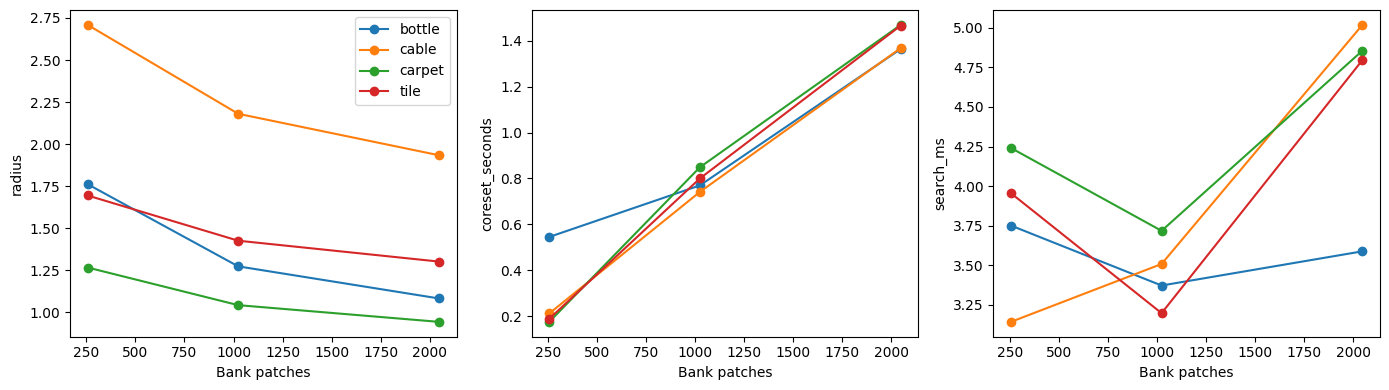

Recomputed choice: budget  aggregation
2048    top1pct        0.765848
        max            0.763366
1024    top1pct        0.761957
        max            0.758711
256     top1pct        0.748237
        max            0.738585


In [15]:
dev=pd.read_csv(report/'development_comparison.csv')
display(dev);display(pd.read_csv(report/'development_macro.csv'))
records=[]
for budget in [256,1024,2048]:
    for category in ['bottle','cable','carpet','tile']:
        r=json.loads((report/f'runs/03-dev-b{budget}-{category}-s2026-v1-result.json').read_text())
        records.append(dict(budget=budget,category=category,radius=r['candidate_coverage']['projected_radius'],
            coreset_seconds=r['coreset_seconds'],search_ms=r['development']['search_p50_ms']))
fig,axes=plt.subplots(1,3,figsize=(14,4))
for category,group in pd.DataFrame(records).groupby('category'):
    for ax,key in zip(axes,['radius','coreset_seconds','search_ms']):
        ax.plot(group.budget,group[key],marker='o',label=category);ax.set_xlabel('Bank patches');ax.set_ylabel(key)
axes[0].legend();plt.tight_layout();plt.show();plt.close(fig)
ranked=dev.groupby(['budget','aggregation']).objective.mean().sort_values(ascending=False)
assert ranked.index[0]==(frozen['configuration']['bank_budget'],frozen['configuration']['aggregation'])
print('Recomputed choice:',ranked.to_string())


### All-budget synthetic reconstruction-free map examples (local)
For each development category, recreate the original fixed fitting-derived
synthetic RGB probe with seed 9901 and verify its mask against the retained
mask. No features are extracted again. Read the original saved distance maps.
Rows: budgets 256/1024/2048; columns: edited RGB, raw map, synthetic mask.
All maps in one category share a display limit derived from normal development
maps. These are proxy edits, never official defects. Licensed pixels stay local.


In [16]:
development_panels=[]
for category in ['bottle','cable','carpet','tile']:
    _,probe_rows=inner_fit_split(read_partition('fit',category))
    images=load_resized(probe_rows,256).cuda()
    probes,masks=make_probes(images,probe_rows)
    saved=[]
    for budget in [256,1024,2048]:
        saved.append(np.load(ROOT/f'outputs/patchcore/03-dev-b{budget}-{category}-s2026-v1/development_maps.npz'))
    limit=max(float(np.quantile(s['normal'],.995)) for s in saved)
    fig,axes=plt.subplots(3,3,figsize=(10,10))
    index=len(probe_rows)
    for i,s in enumerate(saved):
        assert np.array_equal(s['masks'],masks[:,0].cpu().numpy())
        values=[probes[index].cpu().permute(1,2,0).numpy(),pixel_maps(torch.from_numpy(s['proxy'][index:index+1]))[0].numpy(),s['masks'][index]]
        for j,a in enumerate(values):axes[i,j].imshow(a,vmin=0,vmax=limit if j==1 else 1);axes[i,j].axis('off')
        axes[i,0].set_title(category+' / bank '+str([256,1024,2048][i]))
    plt.tight_layout();plt.show();plt.close(fig)


## 17. Candidate decision and compute gate
Read the immutable selection and compute report written before final fits/test
access. The selected proxy advantage is small and single-development-seed
evidence does not establish an optimal architecture. No additional backbone,
normalization or smoothing search was justified within this bounded study.
## 18. Threshold calibration
Only reserved normals calibrate image higher-q95 and independent pooled pixel
higher-q99.5 thresholds; alarm iff score > threshold. Distances are unbounded,
not probabilities. The 4,096-bin pixel bootstrap uses d/(d+s), where s is median
normal-calibration patch distance, to avoid clipping high distances. Exact native
point metrics use raw distances. Threshold and image-metric bootstrap resample
whole images, not independent pixels. Small samples and shift limit FPR control.
## 19. Frozen model and evaluation implementation
The source below is the actual frozen calibration, search-timing and native
evaluation implementation. These definitions execute here; historical official
inference is not repeated. Existing exact metric and bootstrap helpers are reused.


In [17]:
print(json.dumps(frozen,indent=2))
print(json.dumps(json.loads((report/'compute_budget.json').read_text()),indent=2))


{
  "frozen_at_utc": "2026-11-12T18:38:15.737779+00:00",
  "configuration": {
    "bank_budget": 2048,
    "candidate_limit": 20000,
    "projection_dim": 32,
    "seed": 2026,
    "backbone": "resnet18",
    "weights": "IMAGENET1K_V1",
    "layers": [
      "layer2",
      "layer3"
    ],
    "resolution": 256,
    "normalize": false,
    "query_chunk": 512,
    "bank_chunk": 2048,
    "aggregation": "top1pct"
  },
  "seeds": [
    2026,
    2027,
    2028
  ],
  "categories": [
    "bottle",
    "cable",
    "capsule",
    "carpet",
    "grid",
    "hazelnut",
    "leather",
    "metal_nut",
    "pill",
    "screw",
    "tile",
    "toothbrush",
    "transistor",
    "wood",
    "zipper"
  ],
  "selected_variant": "b2048",
  "weight_sha256": "f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec",
  "weight_url": "https://download.pytorch.org/models/resnet18-f37072fd.pth",
  "source_sha256": {
    "src/anomaly_detection/patchcore.py": "8558267cbf0d1794bc5d5c78c6da4757fb7c9

In [18]:
__file__=str(ROOT/'src/anomaly_detection/patchcore_evaluation.py')
"""Frozen distance calibration and exact native PatchCore evaluation.

Primary metrics use raw L2 distances. Binned uncertainty uses only a monotone
calibration-scaled transform, never clipping raw distances to probability range.
"""
from pathlib import Path
from datetime import datetime,timezone
import gc,json,time,traceback,subprocess
import numpy as np
import pandas as pd
from PIL import Image
from scipy.ndimage import label
import torch
from torch.nn import functional as F
from anomaly_detection.patchcore import nearest_neighbors,patch_embeddings,pixel_maps,image_scores,load_bank
from anomaly_detection.patchcore_research import ROOT,Resources,feature_cache,score_embeddings
from anomaly_detection.cnn_research import read_partition
from anomaly_detection.data import autodiscover_data_root,sha256
from anomaly_detection.metrics import binary_metrics,calibrate_normal
from anomaly_detection.pixel_metrics import exact_pixel_metrics,histogram_metrics
from anomaly_detection.tracking import config_hash,record
from anomaly_detection.cnn_evaluation import bootstrap_evaluation as shared_bootstrap


def bootstrap_evaluation(*args):
    result,vectors=shared_bootstrap(*args)
    result['pixel_ci_method']='Whole-image bootstrap; 4096 bins of d/(d+calibration median patch distance); exact raw-distance primary metrics'
    return result,vectors


class PatchPipeline(torch.nn.Module):
    def __init__(self,extractor,bank,config):
        super().__init__()
        self.extractor=extractor;self.bank=bank;self.config=config

    @torch.inference_mode()
    def patches(self,images):
        features=self.extractor(images)
        distances,_=nearest_neighbors(patch_embeddings(features),self.bank)
        return distances.reshape(len(images),32,32)

    def forward(self,images):return pixel_maps(self.patches(images))[:,None]


def calibrate_model(model,category,resolution,seed=2026):
    rows=read_partition('calibration',category)
    features,cache=feature_cache(model.extractor,rows)
    patches=score_embeddings(features,model.bank)
    scores=image_scores(patches,model.config['aggregation']).numpy()
    maps=pixel_maps(patches).numpy()
    threshold=calibrate_normal(scores)
    rng=np.random.default_rng(seed)
    draws=rng.choice(scores,size=(2000,len(scores)),replace=True)
    intervals=np.quantile(np.quantile(draws,.95,axis=1,method='higher'),[.025,.975]).tolist()
    return dict(category=category,images=len(rows),image_threshold=threshold,
        secondary_image_threshold_q99=calibrate_normal(scores,.01),
        pixel_threshold=float(np.quantile(maps,.995,method='higher')),
        image_quantile=.95,pixel_quantile=.995,pixel_calibration_samples=maps.size,
        pixel_score_resolution=256,calibration_scores=scores.tolist(),
        image_threshold_bootstrap_95ci=intervals,
        histogram_scale=max(float(np.median(patches.numpy())),1e-6),
        histogram_transform='d/(d+normal calibration median patch distance), 4096 bins; no raw-score clipping',
        method='Reserved normals only; higher empirical image q95 and pooled pixel q99.5; strict >',
        source_paths_sha256=config_hash(rows[['path','sha256']].to_dict('records')),feature_cache=cache)


@torch.inference_mode()
def benchmark_model(model,calibration_path,resolution,native_shape,output):
    with Image.open(autodiscover_data_root(ROOT)/calibration_path) as image:raw=image.convert('RGB').copy()
    def once():
        start=time.perf_counter()
        array=np.asarray(raw.resize((256,256),Image.Resampling.BILINEAR)).copy()
        x=torch.from_numpy(array).permute(2,0,1)[None].float()/255
        pre=time.perf_counter();x=x.cuda();torch.cuda.synchronize();transfer=time.perf_counter()
        features=model.extractor(x);torch.cuda.synchronize();extracted=time.perf_counter()
        distances,_=nearest_neighbors(patch_embeddings(features),model.bank)
        patches=distances.reshape(1,32,32);torch.cuda.synchronize();searched=time.perf_counter()
        maps=pixel_maps(patches)
        result=F.interpolate(maps[:,None],size=native_shape,mode='bilinear',align_corners=False).cpu().numpy()
        float(image_scores(patches,model.config['aggregation']).item())
        torch.cuda.synchronize();finish=time.perf_counter()
        return np.array([pre-start,transfer-pre,extracted-transfer,searched-extracted,
            searched-transfer,finish-searched,finish-start])*1000
    for _ in range(50):once()
    torch.cuda.reset_peak_memory_stats()
    times=np.stack([once() for _ in range(200)])
    names=['preprocessing','host_to_device','feature_extraction','nearest_neighbor','model','postprocessing','end_to_end']
    pd.DataFrame(times,columns=names).to_csv(output,index=False,lineterminator='\n')
    context={}
    for key,command in [('windows_scheme',['powercfg','/getactivescheme']),
        ('gpu',['nvidia-smi','--query-gpu=name,driver_version,pstate,clocks.gr,temperature.gpu','--format=csv,noheader'])]:
        try:context[key]=subprocess.check_output(command,text=True,timeout=10).strip()
        except (OSError,subprocess.SubprocessError) as exc:context[key]=str(exc)
    return {name:dict(p50_ms=float(np.median(times[:,i])),p95_ms=float(np.quantile(times[:,i],.95)))
            for i,name in enumerate(names)} | dict(warmup=50,iterations=200,batch_size=1,precision='float32',
        scope='Memory-resident decoded RGB -> native raw-distance CPU map + image score; file decode excluded; model=feature extraction+NN',
        power_context_at_end_of_timing=context,peak_inference_allocated_bytes=torch.cuda.max_memory_allocated(),
        peak_inference_reserved_bytes=torch.cuda.max_memory_reserved())


def evaluate_frozen(identifier, training_result, freeze_sha256, extractor):
    """One immutable evaluation reservation per category/seed; never retries itself."""
    from anomaly_detection.cnn_research import code_identity
    freeze_path=ROOT/"configs/patchcore_frozen.json"
    if sha256(freeze_path)!=freeze_sha256:raise ValueError("Frozen confirmation identity mismatch")
    frozen=json.loads(freeze_path.read_text())
    for path, expected_hash in frozen["source_sha256"].items():
        if sha256(ROOT/path)!=expected_hash:raise ValueError("Frozen model/training source changed")
    expected=dict(frozen["configuration"],seed=training_result["configuration"]["seed"])
    if expected!=training_result["configuration"] or expected["seed"] not in frozen["seeds"]:
        raise ValueError("Training configuration differs from frozen policy")
    if training_result["category"] not in frozen["categories"]:
        raise ValueError("Unregistered category")
    if sha256(Path(__file__))!=frozen["evaluation_source_sha256"]:
        raise ValueError("Evaluation implementation changed after freeze")
    if sha256(Path(__file__).with_name("pixel_metrics.py"))!=frozen["pixel_metric_source_sha256"]:
        raise ValueError("Pixel metric implementation changed after freeze")
    result_dir=ROOT/"reports/patchcore/evaluation"
    result_dir.mkdir(parents=True,exist_ok=True)
    local=ROOT/"outputs/patchcore"/identifier
    local.mkdir(parents=True,exist_ok=False)
    category=training_result["category"]
    config=training_result["configuration"]
    entry={"experiment_id":identifier+"-start","model_family":"PatchCoreVariant","categories":[category],
           "hypothesis":"Frozen normal patch-memory confirmation; no further selection",
           "preprocessing":{"resolution":config["resolution"],"native_map":"bilinear, align_corners=False"},
           "hyperparameters":config,"seed":config["seed"],
           "environment":json.loads((ROOT/"reports/environment.json").read_text()),
           "training":{"training_experiment":training_result["experiment_id"],"freeze_sha256":freeze_sha256,
                       "code":{"source_sha256":frozen["source_sha256"],"git_sha":subprocess.check_output(["git","rev-parse","HEAD"],cwd=ROOT,text=True).strip()},"evaluation_source_sha256":sha256(Path(__file__)),
                       "pixel_metric_source_sha256":sha256(Path(__file__).with_name("pixel_metrics.py"))},
           "metrics":{},"calibration":{},"paths":{"local":local.relative_to(ROOT).as_posix()},
           "interpretation":"Reserved before calibration/test inference","decision":"frozen evaluation","status":"started"}
    record(ROOT/"experiments",entry)
    started=time.perf_counter()
    monitor=Resources();monitor.__enter__()
    try:
        checkpoint=ROOT/training_result["checkpoint"]
        if sha256(checkpoint)!=training_result["checkpoint_sha256"]:raise ValueError("Checkpoint identity changed")
        bank,saved=load_bank(checkpoint,category,'cuda')
        if extractor.weight_sha256!=frozen['weight_sha256']:raise ValueError('Pretrained weights changed')
        model=PatchPipeline(extractor,bank,config)
        if saved["category"]!=category or saved['provenance']['phase']!="final" or saved['config']!=config:
            raise ValueError("Expected a fresh category-specific final checkpoint")
        # Calibration occurs and is saved BEFORE test rows/images are loaded.
        calibration=calibrate_model(model,category,config["resolution"],config["seed"])
        with (result_dir/f"{identifier}-calibration.json").open("x") as stream:json.dump(calibration,stream,indent=2)
        rows=read_partition("test",category)
        data_root=autodiscover_data_root(ROOT)
        features,test_cache=feature_cache(extractor,rows)
        patch_distances=score_embeddings(features,bank)
        maps=pixel_maps(patch_distances).numpy()
        np.save(local/'patch_distances.npy',patch_distances.numpy(),allow_pickle=False)
        scores=image_scores(patch_distances,config['aggregation']).numpy()
        labels=rows["mask"].notna().astype(int).to_numpy()
        image_result=binary_metrics(labels,scores,calibration["image_threshold"])
        tn,fp,fn,tp=np.asarray(image_result["confusion_matrix"]).ravel()
        image_counts={"tn":int(tn),"fp":int(fp),"fn":int(fn),"tp":int(tp)}
        secondary=binary_metrics(labels,scores,calibration["secondary_image_threshold_q99"])
        table=rows[["path","category","mask"]].copy()
        table["defect"]=rows.path.str.split("/").str[-2]
        table["label"]=labels;table["score"]=scores
        table["predicted"]=scores>calibration["image_threshold"]
        table["outcome"]=np.select([(labels==0)&~table.predicted,(labels==0)&table.predicted,
                                    (labels==1)&table.predicted],["TN","FP","TP"],default="FN")
        table.to_csv(result_dir/f"{identifier}-images.csv",index=False,lineterminator="\n")
        np.save(local/"model_resolution_maps.npy",maps,allow_pickle=False)
        # Original dimensions from verified inventory, not estimated from resized masks.
        inventory=pd.read_csv(ROOT/"outputs/eda/inventory.csv").set_index("path")
        sizes=[(int(inventory.loc[p,"height"]),int(inventory.loc[p,"width"])) for p in rows.path]
        pixel_count=sum(h*w for h,w in sizes)
        scratch=[]
        for name,dtype in (("scores",np.float32),("truth",np.uint8),("regions",np.float64)):
            path=local/f"native-{name}.dat";scratch.append(path)
        flat_scores=np.memmap(scratch[0],mode="w+",dtype=np.float32,shape=(pixel_count,))
        flat_truth=np.memmap(scratch[1],mode="w+",dtype=np.uint8,shape=(pixel_count,))
        flat_regions=np.memmap(scratch[2],mode="w+",dtype=np.float64,shape=(pixel_count,))
        bins=4096
        positive_hist=np.zeros((len(rows),bins),np.uint32)
        negative_hist=np.zeros_like(positive_hist)
        region_hist=np.zeros((len(rows),bins),np.float64)
        region_counts=[];cursor=0
        pixel_cm=np.zeros((2,2),np.int64)
        for i,(row,size) in enumerate(zip(rows.itertuples(),sizes)):
            with torch.inference_mode():
                native=F.interpolate(torch.from_numpy(maps[i:i+1,None]),size=size,mode="bilinear",align_corners=False).numpy()[0,0]
            if isinstance(row.mask,str):
                mask_path=data_root/row.mask
                if sha256(mask_path)!=row.mask_sha256:raise ValueError("Official mask changed")
                with Image.open(mask_path) as mask_image:truth=(np.asarray(mask_image)>0).astype(np.uint8)
            else:truth=np.zeros(size,np.uint8)
            components,count=label(truth,structure=np.ones((3,3)))
            areas=np.bincount(components.ravel());areas[0]=1
            region_weight=np.where(truth,1/areas[components],0.)
            end=cursor+native.size
            flat_scores[cursor:end]=native.ravel();flat_truth[cursor:end]=truth.ravel();flat_regions[cursor:end]=region_weight.ravel()
            cursor=end;region_counts.append(count)
            idx=np.minimum((native/(native+calibration["histogram_scale"])*bins).astype(np.int64),bins-1)
            positive_hist[i]=np.bincount(idx[truth.astype(bool)],minlength=bins)
            negative_hist[i]=np.bincount(idx[~truth.astype(bool)],minlength=bins)
            region_hist[i]=np.bincount(idx.ravel(),weights=region_weight.ravel(),minlength=bins)
            pred=native>calibration["pixel_threshold"]
            pixel_cm+=np.bincount((2*truth+pred).ravel(),minlength=4).reshape(2,2)
        flat_scores.flush();flat_truth.flush();flat_regions.flush()
        print(identifier,"exact pixel sweep",pixel_count,flush=True)
        pixel_result=exact_pixel_metrics(flat_scores,flat_truth,flat_regions,sum(region_counts))
        ptn,pfp,pfn,ptp=pixel_cm.ravel()
        prec=float(ptp/(ptp+pfp)) if ptp+pfp else 0.
        rec=float(ptp/(ptp+pfn))
        pixel_operating={"precision":prec,"recall":rec,"fpr":float(pfp/(pfp+ptn)),
                         "f1":2*prec*rec/(prec+rec) if prec+rec else 0.,
                         "tp":int(ptp),"fp":int(pfp),"tn":int(ptn),"fn":int(pfn)}
        intervals,bootstrap_vectors=bootstrap_evaluation(labels,scores,calibration["image_threshold"],
                        positive_hist,negative_hist,region_hist,region_counts,category)
        np.savez_compressed(local/"bootstrap_vectors.npz",**bootstrap_vectors)
        np.savez_compressed(local/"native_image_histograms.npz",positive=positive_hist,negative=negative_hist,
                            region=region_hist,region_counts=region_counts)
        binned=histogram_metrics(positive_hist.sum(0),negative_hist.sum(0),region_hist.sum(0),sum(region_counts))
        calibration_rows=read_partition("calibration",category)
        latency=benchmark_model(model,calibration_rows.path.iloc[0],config["resolution"],sizes[0],local/"latency_ms.csv")
        defects=[]
        for defect in sorted(table.loc[table.label.eq(1),"defect"].unique()):
            subset=table[table.defect.isin(["good",defect])]
            values=binary_metrics(subset.label,subset.score,calibration["image_threshold"])
            defects.append({"category":category,"seed":config["seed"],"defect":defect,
                            "defective_images":int(subset.label.sum()),**values})
        monitor.__exit__(None,None,None)
        result={"experiment_id":identifier,"category":category,"seed":config["seed"],
                "training_experiment":training_result["experiment_id"],"checkpoint_sha256":training_result["checkpoint_sha256"],
                "image_auroc":image_result.pop("auroc"),"image_ap":image_result.pop("ap"),**image_result,**image_counts,
                **pixel_result,"pixel_confusion_matrix":pixel_cm.tolist(),"pixel_operating_point":pixel_operating,"secondary_image_q99":secondary,
                "calibration":calibration,"latency":latency,"uncertainty":intervals,
                "bootstrap_binned_pixel_point_estimates":dict(zip(["pixel_auroc","pixel_ap","au_pro"],binned)),
                "training_seconds":training_result["wall_seconds"],
                "coreset_seconds":training_result['coreset_seconds'],
                "original_extraction_seconds":training_result['original_extraction_seconds'],
                "feature_cache_hit_during_fit":training_result['feature_cache']['cache_hit'],
                "test_cache":test_cache,"cpu_peak_rss_bytes":monitor.result['cpu_peak_rss_bytes'],
                "bank_vector_bytes":training_result['bank_vector_bytes'],
                "training_peak_allocated_bytes":training_result["bank_resources"]["peak_gpu_allocated_bytes"],
                "checkpoint_bytes":training_result["checkpoint_bytes"],"parameters":sum(p.numel() for p in extractor.parameters()),
                "evaluation_seconds":time.perf_counter()-started,"per_defect":defects,
                "local_maps":(local/"model_resolution_maps.npy").relative_to(ROOT).as_posix(),
                "maps_sha256":sha256(local/"model_resolution_maps.npy"),
                "freeze_sha256":freeze_sha256,"image_rows":len(rows),"evaluated_at_utc":datetime.now(timezone.utc).isoformat()}
        with (result_dir/f"{identifier}-result.json").open("x") as stream:json.dump(result,stream,indent=2,allow_nan=False)
        entry.update(experiment_id=identifier+"-result",status="completed",metrics=result,calibration=calibration,
                     interpretation="Frozen real-test confirmation; no post-test changes permitted",decision="retain even if disappointing")
        record(ROOT/"experiments",entry)
        # Scratch native vectors are reproducible from retained low-resolution
        # maps and original masks; remove only these three explicitly named files.
        for mapping in (flat_scores,flat_truth,flat_regions):mapping._mmap.close()
        del flat_scores,flat_truth,flat_regions;gc.collect()
        for path in scratch:
            assert path.resolve().is_relative_to((ROOT/"outputs/patchcore").resolve())
            path.unlink()
        return result
    except BaseException as exc:
        if not monitor.done.is_set():monitor.__exit__(None,None,None)
        (local/"failure.txt").write_text(traceback.format_exc(),encoding="utf-8")
        entry.update(experiment_id=identifier+"-failure",status="failed",interpretation=f"{type(exc).__name__}: {exc}",decision="preserve; investigate without retuning")
        record(ROOT/"experiments",entry)
        raise


## 20. All-category evaluation: frozen hypothesis
Hypothesis: one independently sampled normal coreset per category/seed transfers
to real defects with acceptable recall, false alarms and latency. All 15
categories and seeds 2026/2027/2028 are retained. Deterministic features are shared
across seeds; no test-driven bank refit occurs. This is a 45-bank confirmation
cohort, not 45 independent test datasets. The following reads measured results.


In [19]:
runs=pd.read_csv(report/'all_runs.csv')
display(pd.read_csv(report/'all_category_means.csv'))
display(pd.DataFrame(summary['macro']).T)
display(runs[['category','seed','calibration_images','image_threshold','recall','fpr','precision','f1','tn','fp','fn','tp']])
display(pd.read_csv(report/'texture_object.csv'))
print(json.dumps(summary,indent=2))


,category,image_auroc_mean,image_auroc_std,image_ap_mean,image_ap_std,pixel_auroc_mean,pixel_auroc_std,pixel_ap_mean,pixel_ap_std,au_pro_mean,au_pro_std,recall_mean,recall_std,fpr_mean,fpr_std,precision_mean,precision_std,f1_mean,f1_std
0,bottle,1.000000,0.000000,1.000000,0.000000,0.982623,0.000033,0.729022,0.000283,0.940984,0.002879,1.000000,0.000000,0.183333,0.104083,0.945607,0.029141,0.971888,0.015496
1,cable,0.982384,0.004617,0.989787,0.002588,0.979524,0.000752,0.643408,0.002442,0.919865,0.004405,0.891304,0.043478,0.045977,0.009954,0.968666,0.005542,0.927936,0.021683
2,capsule,0.958117,0.008291,0.990892,0.001997,0.987562,0.000131,0.449028,0.002469,0.944825,0.000779,0.712538,0.026484,0.014493,0.025102,0.995935,0.007041,0.830470,0.015326
3,carpet,0.977796,0.002020,0.994039,0.000644,0.989221,0.000149,0.562943,0.002984,0.947401,0.003459,0.985019,0.006487,0.559524,0.082479,0.848730,0.018420,0.911689,0.007747
4,grid,0.919799,0.000835,0.972282,0.001147,0.959403,0.002189,0.299160,0.009398,0.863035,0.003002,0.771930,0.017544,0.095238,0.047619,0.956662,0.021067,0.854359,0.016892
5,hazelnut,0.999881,0.000206,0.999933,0.000116,0.986171,0.000105,0.581337,0.002656,0.945396,0.003897,0.985714,0.000000,0.000000,0.000000,1.000000,0.000000,0.992806,0.000000
6,leather,1.000000,0.000000,1.000000,0.000000,0.992478,0.000062,0.425276,0.001315,0.975162,0.000089,1.000000,0.000000,0.697917,0.198464,0.806378,0.046276,0.892335,0.027963
7,metal_nut,0.991365,0.001571,0.998082,0.000330,0.980164,0.000661,0.850598,0.000899,0.935496,0.000200,0.971326,0.006208,0.106061,0.026243,0.974832,0.006142,0.973070,0.005377
8,pill,0.927078,0.005763,0.986549,0.001048,0.969330,0.000548,0.711380,0.004822,0.933011,0.002531,0.635934,0.033516,0.025641,0.022206,0.992696,0.006348,0.774878,0.024276
9,screw,0.868962,0.010113,0.953894,0.004487,0.983099,0.002236,0.283067,0.018371,0.929158,0.013034,0.540616,0.046282,0.032520,0.014082,0.979649,0.008715,0.695984,0.038974


,mean,seed_std,image_bootstrap_95ci,bootstrap_target
image_auroc,0.967572,0.001277,"[0.9592770074560205, 0.9756856946601472]",exact image metric
image_ap,0.988538,0.000578,"[0.9847127851244424, 0.9920314501679945]",exact image metric
pixel_auroc,0.972944,0.000227,"[0.9692171342072473, 0.9765981734645944]",calibration-scaled 4096-bin pixel approximation
pixel_ap,0.540154,0.002195,"[0.5195418904118031, 0.5629564660378257]",calibration-scaled 4096-bin pixel approximation
au_pro,0.920399,0.000097,"[0.9141796087259443, 0.9268623516974152]",calibration-scaled 4096-bin pixel approximation
recall,0.890435,0.001317,"[0.8768379415665456, 0.9043995820051914]",exact image metric
fpr,0.171806,0.013779,"[0.1420631922686863, 0.20199944431791947]",exact image metric
precision,0.940045,0.003749,"[0.9263036637569828, 0.9531200563519762]",exact image metric
f1,0.904345,0.003414,"[0.8925844350893877, 0.9153958485367998]",exact image metric


,category,seed,calibration_images,image_threshold,recall,fpr,precision,f1,tn,fp,fn,tp
0,bottle,2026,31,1.426850,1.000000,0.300000,0.913043,0.954545,14,6,0,63
1,cable,2026,33,2.498770,0.891304,0.051724,0.964706,0.926554,55,3,10,82
2,capsule,2026,32,1.479213,0.697248,0.000000,1.000000,0.821622,23,0,33,76
3,carpet,2026,42,1.256326,0.977528,0.464286,0.870000,0.920635,15,13,2,87
4,grid,2026,39,1.738757,0.789474,0.047619,0.978261,0.873786,20,1,12,45
5,hazelnut,2026,58,2.470187,0.985714,0.000000,1.000000,0.992806,40,0,1,69
6,leather,2026,36,1.190162,1.000000,0.468750,0.859813,0.924623,17,15,0,92
7,metal_nut,2026,33,2.150675,0.967742,0.090909,0.978261,0.972973,20,2,3,90
8,pill,2026,40,1.958791,0.673759,0.038462,0.989583,0.801688,25,1,46,95
9,screw,2026,48,1.878041,0.537815,0.048780,0.969697,0.691892,39,2,55,64


,kind,image_auroc,image_ap,pixel_auroc,pixel_ap,au_pro,recall,fpr,precision,f1
0,object,0.962917,0.986611,0.978090,0.595725,0.928580,0.866783,0.095594,0.957374,0.898446
1,texture,0.976881,0.992390,0.962652,0.429013,0.904037,0.937739,0.324231,0.905387,0.916142


{
  "categories": 15,
  "seeds": [
    2026,
    2027,
    2028
  ],
  "models": 45,
  "development_runs": 12,
  "macro": {
    "image_auroc": {
      "mean": 0.9675715185721371,
      "seed_std": 0.0012768855854672788,
      "image_bootstrap_95ci": [
        0.9592770074560205,
        0.9756856946601472
      ],
      "bootstrap_target": "exact image metric"
    },
    "image_ap": {
      "mean": 0.9885377014831974,
      "seed_std": 0.0005777320972767818,
      "image_bootstrap_95ci": [
        0.9847127851244424,
        0.9920314501679945
      ],
      "bootstrap_target": "exact image metric"
    },
    "pixel_auroc": {
      "mean": 0.9729438122778666,
      "seed_std": 0.00022656435347136937,
      "image_bootstrap_95ci": [
        0.9692171342072473,
        0.9765981734645944
      ],
      "bootstrap_target": "calibration-scaled 4096-bin pixel approximation"
    },
    "pixel_ap": {
      "mean": 0.540154023315294,
      "seed_std": 0.0021946525834844947,
      "image_bootst

### Confirmation interpretation
Assess all categories, recall/FPR and localization together; AP depends on the
dataset's defect prevalence. The final measured conclusions below discuss weak
categories and practical cost. Seed standard deviation is distinct from the
conditional whole-image bootstrap. Pixel intervals target a disclosed binned
approximation; report its measured bias against exact point metrics.
## 21. Genuine images, maps, overlays, masks and nearest normal references (local)
Seed 2026 throughout. Show first manifest-ordered FP, FN, TP where available and
highest-scoring normal, deduplicating paths. No best seed/example selection.
Heatmaps/overlays use retained raw-distance maps. Cached test embeddings supply
the query; no completed feature extraction is repeated. For defects, mark the
highest-distance grid cell intersecting the display mask; for normals, mark the
highest-distance cell. The reference is its actual bank nearest neighbor's
source fitting image/cell. Grid cells are 8x8 input pixels, **not the full CNN
receptive field**. The display limit is twice the normal-calibrated pixel
threshold, with no test-score normalization. Primary metrics use native masks.


In [20]:
data_root=autodiscover_data_root(ROOT)
failure_examples=[]
for category in CATEGORIES:
    identifier=f"03-test-{frozen['selected_variant']}-{category}-s2026-v1"
    r=json.loads((report/f'evaluation/{identifier}-result.json').read_text())
    fit=json.loads((report/f"runs/{r['training_experiment']}-result.json").read_text())
    bank,saved=load_bank(ROOT/fit['checkpoint'],category,'cuda')
    rows=read_partition('fit',category)
    table=pd.read_csv(report/f'evaluation/{identifier}-images.csv')
    maps=np.load(ROOT/r['local_maps'],mmap_mode='r')
    patches=np.load((ROOT/r['local_maps']).parent/'patch_distances.npy',mmap_mode='r')
    embeddings=np.load(ROOT/r['test_cache']['path'],mmap_mode='r')
    choices=[]
    for outcome in ['FP','FN','TP']:
        subset=table[table.outcome.eq(outcome)]
        if len(subset):choices.append(subset.iloc[0])
    choices.append(table[table.label.eq(0)].sort_values('score',ascending=False).iloc[0])
    unique={}
    for row in choices:
        if row.path not in unique:unique[row.path]=row
    choices=list(unique.values());fig,axes=plt.subplots(len(choices),5,figsize=(15,3*len(choices)),squeeze=False)
    for i,row in enumerate(choices):
        with Image.open(data_root/row.path) as image:rgb=np.asarray(image.convert('RGB').resize((256,256),Image.Resampling.BILINEAR)).copy()
        if isinstance(row['mask'],str):
            with Image.open(data_root/row['mask']) as image:mask=np.asarray(image.resize((256,256),Image.Resampling.NEAREST))>0
        else:mask=np.zeros((256,256),bool)
        heat=np.array(maps[int(row.name)]);coarse=np.array(patches[int(row.name)])
        assert np.isclose(image_scores(torch.from_numpy(coarse[None]),frozen['configuration']['aggregation']).item(),row.score,atol=1e-6)
        q=torch.from_numpy(np.array(embeddings[int(row.name)])).cuda()
        replay,neighbors=nearest_neighbors(q,bank)
        cell_mask=torch.nn.functional.adaptive_max_pool2d(torch.from_numpy(mask.astype(np.float32))[None,None],(32,32))[0,0].bool().numpy()
        choice=int(np.where(cell_mask,coarse,-np.inf).argmax()) if cell_mask.any() else int(coarse.argmax())
        source_index=int(saved['indices'][int(neighbors[choice])]);source_image=source_index//1024;source_cell=source_index%1024
        normal_path=rows.path.iloc[source_image]
        with Image.open(data_root/normal_path) as image:reference=np.asarray(image.convert('RGB').resize((256,256),Image.Resampling.BILINEAR)).copy()
        alarm=heat>r['calibration']['pixel_threshold'];overlay=rgb.astype(float)/255
        overlay[alarm]=.5*overlay[alarm]+np.array([.5,0,0])
        for j,a in enumerate([rgb,heat,overlay,mask,reference]):
            axes[i,j].imshow(a,vmin=0,vmax=2*r['calibration']['pixel_threshold'] if j==1 else (255 if j in [0,4] else 1));axes[i,j].axis('off')
        for j,cell,color in [(0,choice,'cyan'),(4,source_cell,'yellow')]:
            axes[i,j].add_patch(Rectangle(((cell%32)*8,(cell//32)*8),8,8,fill=False,edgecolor=color,linewidth=1))
        axes[i,0].set_title(f'{category} {row.outcome} score={row.score:.3f}')
        axes[i,4].set_title('Nearest fitting normal grid cell')
        top=torch.from_numpy(coarse).flatten().topk(11).indices.numpy()
        failure_examples.append(dict(category=category,path=row.path,outcome=row.outcome,score=row.score,
            image_threshold=r['calibration']['image_threshold'],pixel_threshold=r['calibration']['pixel_threshold'],
            mask_pixels=int(mask.sum()),mean_distance_inside=float(heat[mask].mean()) if mask.any() else None,
            mean_distance_outside=float(heat[~mask].mean()),predicted_pixel_fraction=float(alarm.mean()),
            top_patch_defect_overlap=float(cell_mask.ravel()[top].mean()) if mask.any() else None,
            nearest_reference=normal_path,query_cell=choice,reference_cell=source_cell,nearest_distance=float(replay[choice]),
            cached_replay_max_abs_difference=float(np.abs(replay.cpu().numpy().reshape(32,32)-coarse).max())))
    plt.tight_layout();plt.show();plt.close(fig)
pd.DataFrame(failure_examples).to_csv(report/'failure_examples.csv',index=False,lineterminator=chr(10))


## 22. Failure analysis: observed diagnostics
Read actual FP/FN maps and nearest normal references above. Coarse-grid overlap
is a descriptive diagnostic, not native pixel precision. High normal distances
can reflect incomplete bank coverage or feature mismatch; the reference panels
and coverage table provide evidence, not proof of one cause. Local features may
miss structural arrangements and downsampling can limit fine scratches, but a
controlled ablation would be needed to isolate those mechanisms. Native mask
size groups and defect-type recall document actual outcomes without refitting.


In [21]:
display(pd.read_csv(report/'failure_examples.csv'))
display(pd.read_csv(report/'memory_coverage.csv'))
display(pd.read_csv(report/'small_defect_summary.csv'))
display(pd.read_csv(report/'defect_type_size_summary.csv'))
thresholds=[]
for path in sorted((report/'evaluation').glob('*-result.json')):
    r=json.loads(path.read_text());c=r['calibration']
    thresholds.append(dict(category=r['category'],seed=r['seed'],n=c['images'],threshold=c['image_threshold'],
        low=c['image_threshold_bootstrap_95ci'][0],high=c['image_threshold_bootstrap_95ci'][1],test_fpr=r['fpr']))
display(pd.DataFrame(thresholds))


,category,path,outcome,score,image_threshold,pixel_threshold,mask_pixels,mean_distance_inside,mean_distance_outside,predicted_pixel_fraction,top_patch_defect_overlap,nearest_reference,query_cell,reference_cell,nearest_distance,cached_replay_max_abs_difference
0,bottle,bottle/test/good/001.png,FP,1.469823,1.426850,1.280624,0,NaN,0.811652,0.015427,NaN,bottle/train/good/053.png,757,756,1.629198,0.0
1,bottle,bottle/test/broken_large/000.png,TP,3.250125,1.426850,1.280624,7131,2.774872,1.046575,0.321442,1.000000,bottle/train/good/002.png,789,495,3.345479,0.0
2,bottle,bottle/test/good/019.png,FP,1.548923,1.426850,1.280624,0,NaN,0.872649,0.040283,NaN,bottle/train/good/012.png,729,698,1.736368,0.0
3,cable,cable/test/good/013.png,FP,2.524504,2.498770,2.314226,0,NaN,1.733492,0.015457,NaN,cable/train/good/118.png,684,683,2.715162,0.0
4,cable,cable/test/cable_swap/001.png,FN,2.497769,2.498770,2.314226,3846,2.267890,1.788369,0.040131,0.636364,cable/train/good/104.png,464,367,2.551335,0.0
5,cable,cable/test/bent_wire/000.png,TP,2.955525,2.498770,2.314226,1446,2.671809,1.770698,0.054199,0.909091,cable/train/good/053.png,589,717,3.049123,0.0
6,cable,cable/test/good/041.png,FP,2.537580,2.498770,2.314226,0,NaN,1.785440,0.024277,NaN,cable/train/good/116.png,429,333,2.672099,0.0
7,capsule,capsule/test/crack/000.png,FN,1.434997,1.479213,1.152282,164,1.244598,0.742647,0.019089,0.272727,capsule/train/good/156.png,634,634,1.514230,0.0
8,capsule,capsule/test/crack/001.png,TP,3.492949,1.479213,1.152282,1525,3.023828,0.957144,0.212692,1.000000,capsule/train/good/127.png,550,518,3.750214,0.0
9,capsule,capsule/test/good/006.png,TN,1.455172,1.479213,1.152282,0,NaN,0.757037,0.040573,NaN,capsule/train/good/041.png,552,584,1.558451,0.0


,category,seed,bank_size,unique_patch_indices,fitting_images,represented_fitting_images,fraction_fitting_images_represented,max_bank_fraction_from_one_image,candidate_projected_radius
0,bottle,2026,2048,2048,147,147,1.0,0.018066,1.118712
1,cable,2026,2048,2048,158,158,1.0,0.011719,1.906542
2,capsule,2026,2048,2048,155,155,1.0,0.016602,0.917088
3,carpet,2026,2048,2048,196,196,1.0,0.013184,0.940522
4,grid,2026,2048,2048,186,186,1.0,0.011230,1.261953
5,hazelnut,2026,2048,2048,275,275,1.0,0.007812,1.760842
6,leather,2026,2048,2048,173,173,1.0,0.011230,0.928618
7,metal_nut,2026,2048,2048,154,154,1.0,0.016602,1.652324
8,pill,2026,2048,2048,187,187,1.0,0.011230,1.406881
9,screw,2026,2048,2048,224,224,1.0,0.010254,1.406992


,size_group,images,recall,median_mask_fraction
0,at most 0.1%,17,0.647059,0.000861
1,0.1% to 1%,482,0.751037,0.004050
2,above 1%,759,0.938076,0.031327


,category,defect,images,recall,median_mask_fraction
0,bottle,broken_large,20,1.000000,0.118670
1,bottle,broken_small,22,1.000000,0.024370
2,bottle,contamination,21,1.000000,0.072479
3,cable,bent_wire,13,1.000000,0.035990
4,cable,cable_swap,12,0.333333,0.058182
...,...,...,...,...,...
68,zipper,fabric_border,17,1.000000,0.018437
69,zipper,fabric_interior,16,0.937500,0.019763
70,zipper,rough,17,1.000000,0.041537
71,zipper,split_teeth,18,1.000000,0.030675


,category,seed,n,threshold,low,high,test_fpr
0,bottle,2026,31,1.426850,1.385382,1.497305,0.300000
1,bottle,2027,31,1.461277,1.388385,1.474003,0.150000
2,bottle,2028,31,1.472994,1.381883,1.481544,0.100000
3,cable,2026,33,2.498770,2.430747,2.538702,0.051724
4,cable,2027,33,2.489460,2.444917,2.514508,0.051724
5,cable,2028,33,2.538866,2.446834,2.576549,0.034483
6,capsule,2026,32,1.479213,1.272507,1.679742,0.000000
7,capsule,2027,32,1.475752,1.273044,1.890448,0.000000
8,capsule,2028,32,1.434140,1.274698,1.843914,0.043478
9,carpet,2026,42,1.256326,1.200443,1.284214,0.464286


## 23. Runtime, GPU/CPU memory and storage
Fitting time covers cache access, coreset construction and bank saving; no CNN
training occurs. Unique extraction-stage time includes image loading, GPU work,
transfer and cache writes, and is deduplicated by cache identity. RSS is sampled
at 20 Hz; short spikes may be missed. Evaluation RSS includes exact native metric
scratch work and differs from isolated inference memory. CUDA allocation uses
allocator counters. Bank bytes exclude the single shared frozen extractor.
Batch-one latency: 50 warmups, 200 synchronized iterations, already decoded RGB
through native CPU map/image score, disk decode excluded. Feature extraction and
NN are measured separately; model is their combined elapsed stage. Compare p50,
p95 and end-to-end, not just cached-embedding search throughput.


In [22]:
display(runs[['category','seed','coreset_seconds','extraction_p50_ms','nn_p50_ms','model_p50_ms','model_p95_ms','end_to_end_p50_ms','end_to_end_p95_ms','cpu_peak_rss_gib','train_peak_vram_gib','inference_peak_vram_gib','checkpoint_bytes']])
print(json.dumps(summary['shared_backbone_storage'],indent=2))
print('Unique feature caches:',summary['deterministic_feature_caches'],'unique extraction-stage seconds:',summary['unique_extraction_stage_seconds'])


,category,seed,coreset_seconds,extraction_p50_ms,nn_p50_ms,model_p50_ms,model_p95_ms,end_to_end_p50_ms,end_to_end_p95_ms,cpu_peak_rss_gib,train_peak_vram_gib,inference_peak_vram_gib,checkpoint_bytes
0,bottle,2026,1.609292,11.69215,3.51315,15.25285,16.753365,32.07285,35.346035,3.019363,0.602559,0.071207,3182669
1,cable,2026,1.318966,12.36085,3.67770,16.07130,17.640610,35.38760,38.849215,5.468700,0.680073,0.078438,3183821
2,capsule,2026,1.295325,11.79655,3.57410,15.30830,17.134835,33.90145,37.295185,4.711670,0.666035,0.078077,3183757
3,carpet,2026,1.332230,11.91095,3.58595,15.49695,17.369430,34.58805,39.073525,4.424408,0.831196,0.078438,3188621
4,grid,2026,1.320092,11.93775,3.55040,15.46390,17.591415,34.46570,38.446640,3.488255,0.790913,0.078438,3187021
5,hazelnut,2026,1.379747,11.80540,3.51925,15.40085,17.529120,34.15980,37.826110,4.297665,1.149434,0.078438,3198733
6,leather,2026,1.323232,11.54325,3.42670,14.96695,16.311005,33.62520,36.516540,4.721489,0.738545,0.078438,3185997
7,metal_nut,2026,1.334072,11.67500,3.69465,15.44195,19.222295,31.14930,37.099080,2.956211,0.662007,0.063880,3183949
8,pill,2026,1.366159,11.61385,3.48955,15.16615,16.665315,30.64560,33.392490,4.197281,0.794941,0.066305,3187149
9,screw,2026,1.298850,11.60395,3.50540,15.21035,17.042860,33.96340,38.794150,5.765881,0.943989,0.078438,3191757


{
  "path": "checkpoints/patchcore/shared-resnet18-features.pt",
  "sha256": "2192b8a31687274b2abcb7cc59cd35e1c3267ce09e9acbdb70f55291854b9949",
  "bytes": 11179957,
  "parameters": 2782784,
  "trainable_parameters": 0,
  "original_weight_file_bytes": 46830571,
  "original_weight_sha256": "f37072fd47e89c5e827621c5baffa7500819f7896bbacec160b1a16c560e07ec",
  "scope": "One shared frozen layer1-3 feature extractor, not repeated per category or seed"
}
Unique feature caches: 45 unique extraction-stage seconds: 32.80025419999947


## 24. Exact stored comparison: CNN, AE and PatchCore variant
Same categories, partitions, normal calibration policy and native exact metrics.
Different pretrained priors, objectives and score aggregations make this a
complete-pipeline comparison, not an isolated backbone causal study. The image
bootstrap differences are paired by the same official images and draws, shared
across fitted seeds; they are conditional on these fitted models. Pixel primary
metrics are exact; binned uncertainty transforms differ across families, so
paired pixel confidence intervals are deliberately not claimed.


In [23]:
display(pd.read_csv(report/'model_macro_comparison.csv'))
display(pd.read_csv(report/'paired_image_difference_intervals.csv'))
display(pd.read_csv(report/'paired_prediction_disagreements.csv'))
for name in ['cnn','ae']:
    display(pd.read_csv(report/f'{name}_category_comparison.csv'))
    display(pd.read_csv(report/f'{name}_category_costs.csv'))


,Unnamed: 0,Basic CNN,Autoencoder,PatchCore variant
0,image_auroc,0.712589,0.634623,0.967572
1,image_ap,0.858954,0.827916,0.988538
2,pixel_auroc,0.785832,0.690002,0.972944
3,pixel_ap,0.235382,0.110897,0.540154
4,au_pro,0.549807,0.449350,0.920399
5,recall,0.401760,0.235000,0.890435
6,fpr,0.098341,0.093944,0.171806
7,precision,0.873299,0.789620,0.940045
8,f1,0.510593,0.314635,0.904345


,comparison,metric,point_difference,low,high,method
0,Basic CNN,image_auroc,0.254983,0.236742,0.273794,"Paired whole-image within category, same draws..."
1,Basic CNN,image_ap,0.129583,0.113420,0.141616,"Paired whole-image within category, same draws..."
2,Basic CNN,recall,0.488675,0.466170,0.510559,"Paired whole-image within category, same draws..."
3,Basic CNN,fpr,0.073465,0.042164,0.105116,"Paired whole-image within category, same draws..."
4,Basic CNN,precision,0.066746,0.041221,0.105468,"Paired whole-image within category, same draws..."
5,Basic CNN,f1,0.393752,0.373579,0.416591,"Paired whole-image within category, same draws..."
6,Autoencoder,image_auroc,0.332949,0.307232,0.357933,"Paired whole-image within category, same draws..."
7,Autoencoder,image_ap,0.160622,0.140236,0.176272,"Paired whole-image within category, same draws..."
8,Autoencoder,recall,0.655435,0.632817,0.678337,"Paired whole-image within category, same draws..."
9,Autoencoder,fpr,0.077862,0.042989,0.110859,"Paired whole-image within category, same draws..."


,category,seed,comparison,pc_only_detected_defects,baseline_only_detected_defects,pc_only_false_alarms,baseline_only_false_alarms
0,bottle,2026,Basic CNN,39,0,6,0
1,bottle,2026,Autoencoder,39,0,6,2
2,cable,2026,Basic CNN,82,1,3,1
3,cable,2026,Autoencoder,76,2,1,1
4,capsule,2026,Basic CNN,62,0,0,0
...,...,...,...,...,...,...,...
85,transistor,2028,Autoencoder,33,0,5,1
86,wood,2028,Basic CNN,13,0,4,0
87,wood,2028,Autoencoder,41,0,4,0
88,zipper,2028,Basic CNN,87,0,3,0


,category,image_auroc_mean_pc,image_auroc_std_pc,image_ap_mean_pc,image_ap_std_pc,pixel_auroc_mean_pc,pixel_auroc_std_pc,pixel_ap_mean_pc,pixel_ap_std_pc,au_pro_mean_pc,...,au_pro_mean_cnn,au_pro_std_cnn,recall_mean_cnn,recall_std_cnn,fpr_mean_cnn,fpr_std_cnn,precision_mean_cnn,precision_std_cnn,f1_mean_cnn,f1_std_cnn
0,bottle,1.000000,0.000000,1.000000,0.000000,0.982623,0.000033,0.729022,0.000283,0.940984,...,0.433466,0.082948,0.444444,0.063492,0.033333,0.028868,0.978405,0.018818,0.609029,0.057472
1,cable,0.982384,0.004617,0.989787,0.002588,0.979524,0.000752,0.643408,0.002442,0.919865,...,0.335806,0.084016,0.079710,0.084429,0.057471,0.035891,0.600000,0.173205,0.135010,0.136040
2,capsule,0.958117,0.008291,0.990892,0.001997,0.987562,0.000131,0.449028,0.002469,0.944825,...,0.200637,0.055622,0.116208,0.029491,0.028986,0.050204,0.939394,0.104973,0.206526,0.049472
3,carpet,0.977796,0.002020,0.994039,0.000644,0.989221,0.000149,0.562943,0.002984,0.947401,...,0.488622,0.244580,0.329588,0.096873,0.214286,0.214286,0.830054,0.149146,0.468275,0.119744
4,grid,0.919799,0.000835,0.972282,0.001147,0.959403,0.002189,0.299160,0.009398,0.863035,...,0.801374,0.006315,0.748538,0.020258,0.047619,0.000000,0.977089,0.000597,0.847582,0.013132
5,hazelnut,0.999881,0.000206,0.999933,0.000116,0.986171,0.000105,0.581337,0.002656,0.945396,...,0.704566,0.142532,0.619048,0.054085,0.000000,0.000000,1.000000,0.000000,0.763769,0.042048
6,leather,1.000000,0.000000,1.000000,0.000000,0.992478,0.000062,0.425276,0.001315,0.975162,...,0.855895,0.134122,0.887681,0.080121,0.302083,0.236621,0.898817,0.079192,0.890761,0.052148
7,metal_nut,0.991365,0.001571,0.998082,0.000330,0.980164,0.000661,0.850598,0.000899,0.935496,...,0.548068,0.121797,0.225806,0.116308,0.090909,0.078730,0.885714,0.103016,0.353940,0.154371
8,pill,0.927078,0.005763,0.986549,0.001048,0.969330,0.000548,0.711380,0.004822,0.933011,...,0.770669,0.023451,0.340426,0.080552,0.038462,0.038462,0.981842,0.016359,0.501631,0.084272
9,screw,0.868962,0.010113,0.953894,0.004487,0.983099,0.002236,0.283067,0.018371,0.929158,...,0.377411,0.104574,0.036415,0.017493,0.495935,0.443295,0.437500,0.488141,0.058474,0.023520


,category,model_p50_ms_pc,model_p95_ms_pc,end_to_end_p50_ms_pc,end_to_end_p95_ms_pc,train_peak_vram_gib_pc,checkpoint_bytes_pc,training_seconds_pc,model_p50_ms_cnn,model_p95_ms_cnn,end_to_end_p50_ms_cnn,end_to_end_p95_ms_cnn,train_peak_vram_gib_cnn,checkpoint_bytes_cnn,training_seconds_cnn
0,bottle,15.267267,17.078825,32.391400,35.755438,0.623392,3.182712e+06,2.697035,3.769317,6.022445,13.368867,16.010852,0.452145,343117.0,7.892708
1,cable,15.687750,17.371325,34.821117,38.608055,0.680073,3.183864e+06,2.512590,3.761300,4.931425,15.634017,18.048133,0.454037,343117.0,8.484057
2,capsule,15.258533,17.064028,34.119983,37.757978,0.666035,3.183800e+06,2.434317,3.690650,5.392752,14.726183,17.240370,0.453304,343117.0,9.268997
3,carpet,15.749350,17.239240,34.906217,38.251430,0.831196,3.188621e+06,2.750469,3.684367,5.016903,14.961483,17.548760,0.462764,343117.0,13.920918
4,grid,15.192883,16.953202,33.938817,37.504643,0.790913,3.187064e+06,2.725816,3.207300,4.822390,14.466900,17.766400,0.460933,343117.0,10.832299
5,hazelnut,15.146517,16.952273,33.985083,37.228637,1.149434,3.198733e+06,3.411754,3.439683,5.146650,15.023367,17.991762,0.480465,343117.0,21.235942
6,leather,15.105450,19.467182,33.879767,43.314160,0.738545,3.186040e+06,2.708216,3.632117,5.183567,15.056283,17.925558,0.457333,343117.0,11.741614
7,metal_nut,15.352750,18.289073,30.456500,35.462347,0.662007,3.183992e+06,2.557783,3.659267,5.328182,10.541817,13.013842,0.453304,343117.0,7.591351
8,pill,15.248867,16.770978,31.148250,34.104653,0.794941,3.187192e+06,2.822661,3.673400,5.461145,11.730067,14.446030,0.461116,343117.0,10.976285
9,screw,15.322267,17.014510,34.003117,37.738438,0.943989,3.191800e+06,2.955951,2.473167,3.607505,11.493450,13.967820,0.468868,343117.0,11.416574


,category,image_auroc_mean_pc,image_auroc_std_pc,image_ap_mean_pc,image_ap_std_pc,pixel_auroc_mean_pc,pixel_auroc_std_pc,pixel_ap_mean_pc,pixel_ap_std_pc,au_pro_mean_pc,...,au_pro_mean_ae,au_pro_std_ae,recall_mean_ae,recall_std_ae,fpr_mean_ae,fpr_std_ae,precision_mean_ae,precision_std_ae,f1_mean_ae,f1_std_ae
0,bottle,1.000000,0.000000,1.000000,0.000000,0.982623,0.000033,0.729022,0.000283,0.940984,...,0.297197,0.011349,0.391534,0.009164,0.100000,0.000000,0.924976,0.001645,0.550146,0.009370
1,cable,0.982384,0.004617,0.989787,0.002588,0.979524,0.000752,0.643408,0.002442,0.919865,...,0.277514,0.017736,0.097826,0.010870,0.040230,0.009954,0.792929,0.057363,0.174135,0.018492
2,capsule,0.958117,0.008291,0.990892,0.001997,0.987562,0.000131,0.449028,0.002469,0.944825,...,0.481534,0.016259,0.137615,0.137615,0.130435,0.043478,0.571895,0.495882,0.218600,0.210344
3,carpet,0.977796,0.002020,0.994039,0.000644,0.989221,0.000149,0.562943,0.002984,0.947401,...,0.128118,0.003575,0.011236,0.000000,0.035714,0.000000,0.500000,0.000000,0.021978,0.000000
4,grid,0.919799,0.000835,0.972282,0.001147,0.959403,0.002189,0.299160,0.009398,0.863035,...,0.311128,0.015203,0.005848,0.010129,0.000000,0.000000,0.333333,0.577350,0.011494,0.019909
5,hazelnut,0.999881,0.000206,0.999933,0.000116,0.986171,0.000105,0.581337,0.002656,0.945396,...,0.901745,0.009332,0.676190,0.008248,0.000000,0.000000,1.000000,0.000000,0.806799,0.005855
6,leather,1.000000,0.000000,1.000000,0.000000,0.992478,0.000062,0.425276,0.001315,0.975162,...,0.612910,0.041104,0.927536,0.065519,0.875000,0.108253,0.753358,0.014035,0.830560,0.024765
7,metal_nut,0.991365,0.001571,0.998082,0.000330,0.980164,0.000661,0.850598,0.000899,0.935496,...,0.307308,0.008335,0.025090,0.006208,0.121212,0.026243,0.466667,0.115470,0.047619,0.011783
8,pill,0.927078,0.005763,0.986549,0.001048,0.969330,0.000548,0.711380,0.004822,0.933011,...,0.782129,0.006343,0.170213,0.049645,0.012821,0.022206,0.989899,0.017495,0.288192,0.069810
9,screw,0.868962,0.010113,0.953894,0.004487,0.983099,0.002236,0.283067,0.018371,0.929158,...,0.729530,0.007445,0.064426,0.004852,0.000000,0.000000,1.000000,0.000000,0.121027,0.008587


,category,model_p50_ms_pc,model_p95_ms_pc,end_to_end_p50_ms_pc,end_to_end_p95_ms_pc,train_peak_vram_gib_pc,checkpoint_bytes_pc,training_seconds_pc,model_p50_ms_ae,model_p95_ms_ae,end_to_end_p50_ms_ae,end_to_end_p95_ms_ae,train_peak_vram_gib_ae,checkpoint_bytes_ae,training_seconds_ae
0,bottle,15.267267,17.078825,32.391400,35.755438,0.623392,3.182712e+06,2.697035,2.864550,4.445168,12.475400,14.777047,0.578810,131133.0,28.187784
1,cable,15.687750,17.371325,34.821117,38.608055,0.680073,3.183864e+06,2.512590,3.049900,5.309223,14.759283,17.123848,0.581130,131133.0,27.940317
2,capsule,15.258533,17.064028,34.119983,37.757978,0.666035,3.183800e+06,2.434317,2.411817,4.982310,11.463550,14.268513,0.580031,131133.0,27.154448
3,carpet,15.749350,17.239240,34.906217,38.251430,0.831196,3.188621e+06,2.750469,2.978800,5.091748,14.449250,17.118772,0.589491,131133.0,34.536154
4,grid,15.192883,16.953202,33.938817,37.504643,0.790913,3.187064e+06,2.725816,2.934983,5.099530,14.364650,16.993115,0.587660,131133.0,32.564738
5,hazelnut,15.146517,16.952273,33.985083,37.228637,1.149434,3.198733e+06,3.411754,2.962917,4.833607,14.441483,17.152077,0.607192,131133.0,48.398852
6,leather,15.105450,19.467182,33.879767,43.314160,0.738545,3.186040e+06,2.708216,3.053150,5.377240,14.715183,17.291372,0.584059,131133.0,30.338127
7,metal_nut,15.352750,18.289073,30.456500,35.462347,0.662007,3.183992e+06,2.557783,2.739083,4.908653,10.075867,12.761532,0.580031,131133.0,27.368022
8,pill,15.248867,16.770978,31.148250,34.104653,0.794941,3.187192e+06,2.822661,2.767167,4.105257,10.785333,13.029853,0.588759,131133.0,32.815485
9,screw,15.322267,17.014510,34.003117,37.738438,0.943989,3.191800e+06,2.955951,2.986733,5.329357,14.686800,17.548333,0.595595,131133.0,38.467424


### Ranking curves and normal calibration shift
Seed 2026 is fixed for display, not selected as the best seed. All three seeds
remain in the primary summaries. Curves read retained scores only. Normal-score
histograms use common within-category bins and show the frozen threshold; they
do not recalibrate from test normals. Recall and false-alarm behavior matter
alongside AUROC and pixel localization.


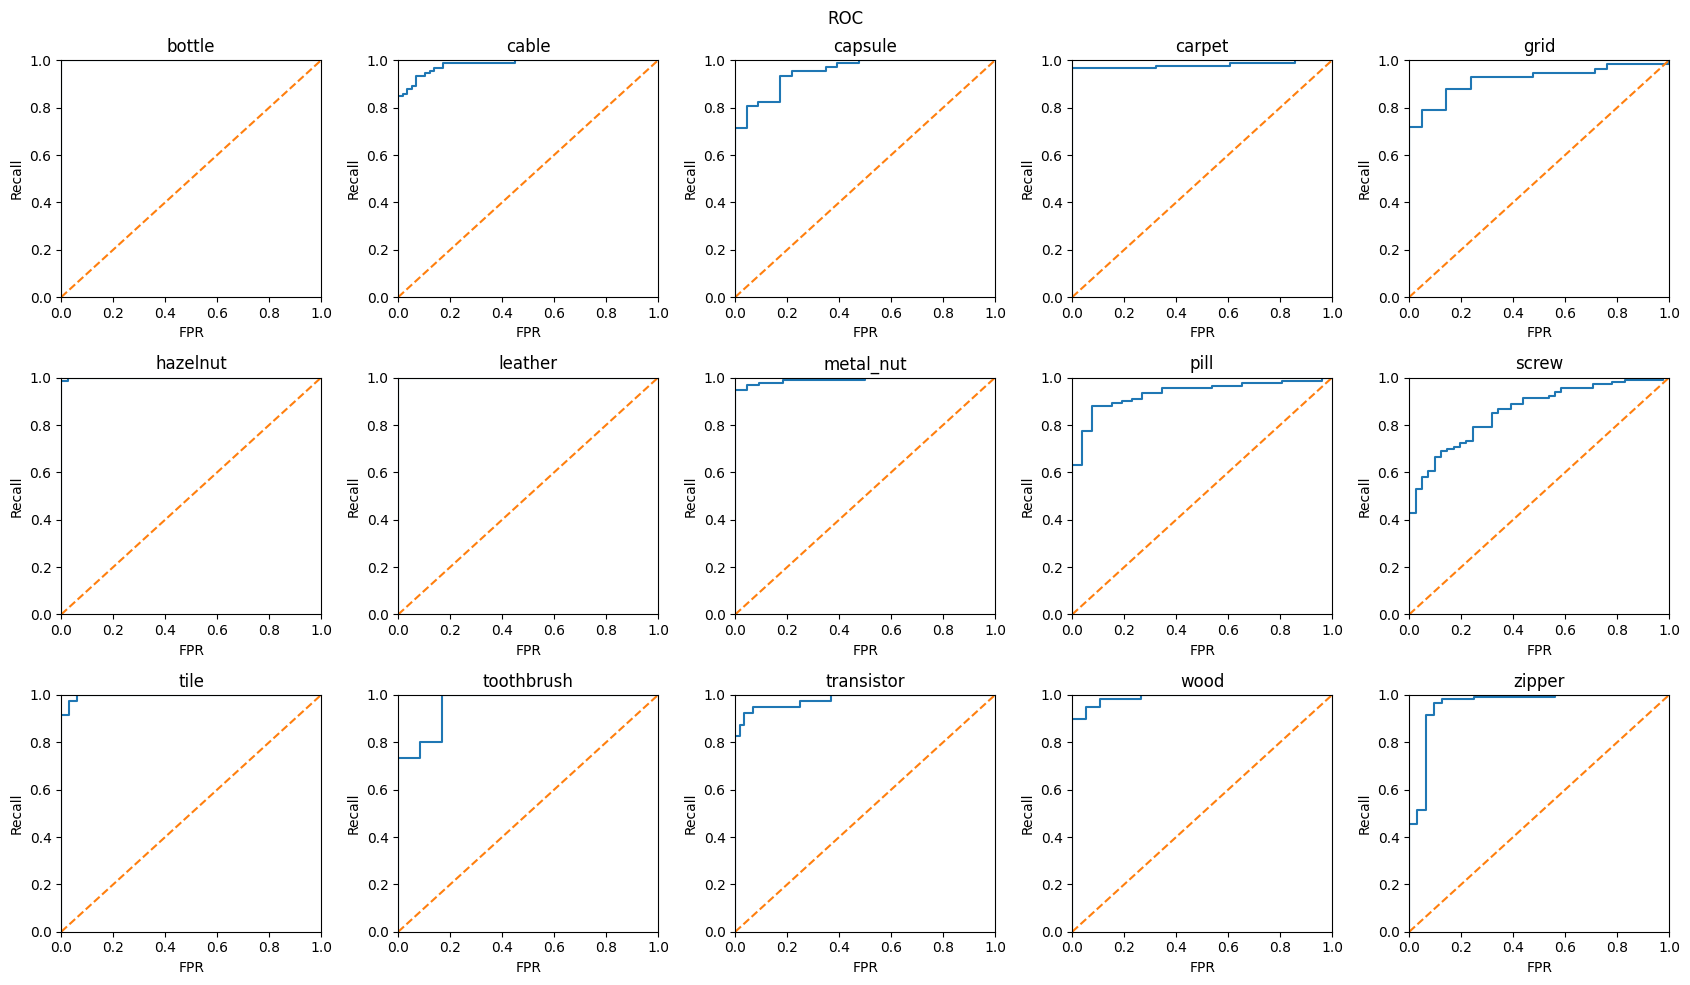

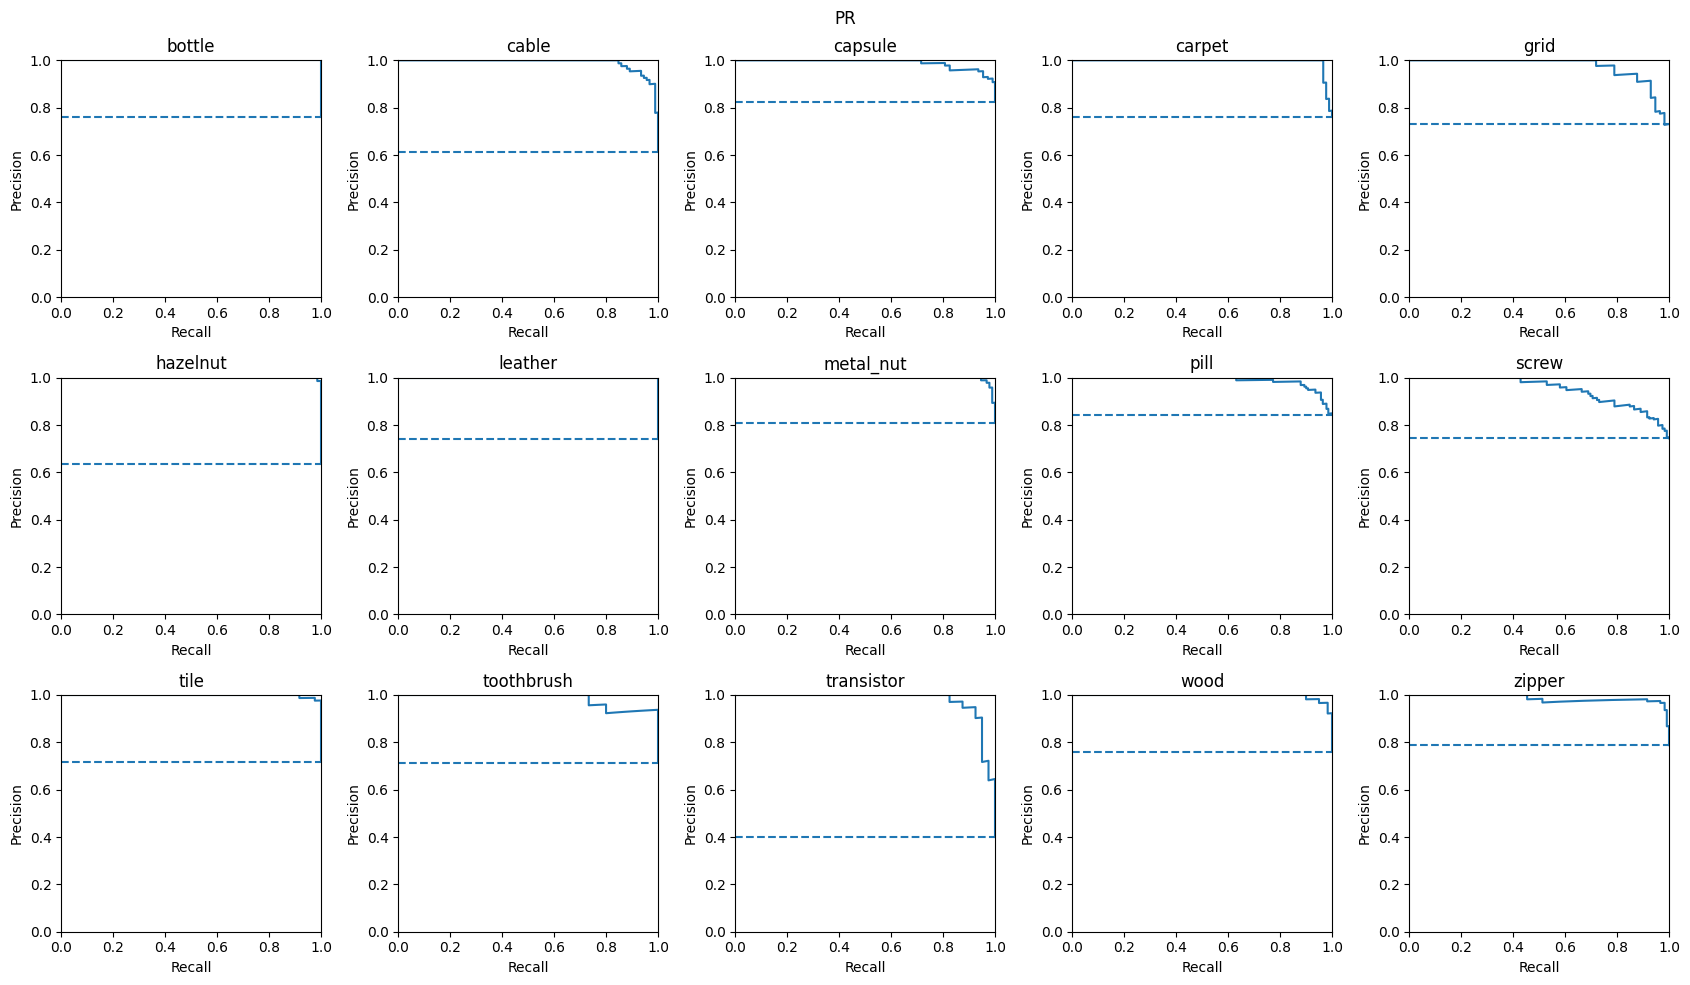

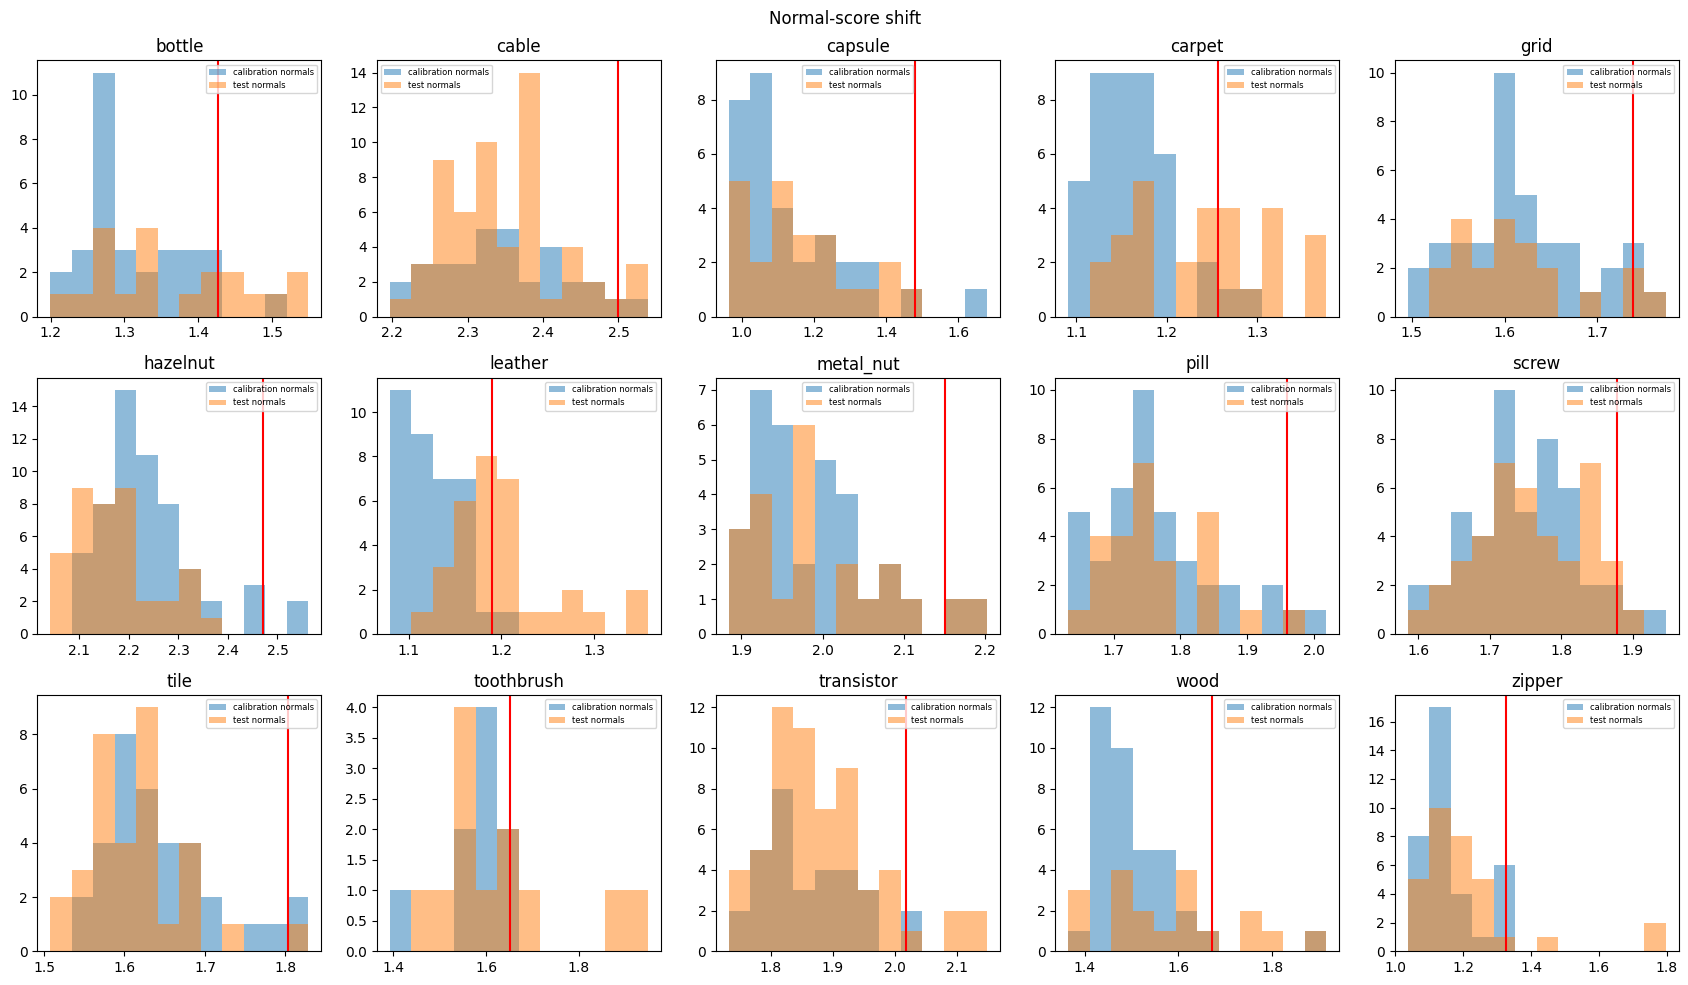

In [24]:
from sklearn.metrics import roc_curve,precision_recall_curve
for kind in ['ROC','PR','Normal-score shift']:
    fig,axes=plt.subplots(3,5,figsize=(17,10))
    for ax,category in zip(axes.flat,CATEGORIES):
        identifier=f"03-test-{frozen['selected_variant']}-{category}-s2026-v1"
        table=pd.read_csv(report/f'evaluation/{identifier}-images.csv')
        calibration=json.loads((report/f'evaluation/{identifier}-calibration.json').read_text())
        if kind=='ROC':
            x,y,_=roc_curve(table.label,table.score);ax.plot(x,y);ax.plot([0,1],[0,1],'--');ax.set_xlabel('FPR');ax.set_ylabel('Recall')
        elif kind=='PR':
            y,x,_=precision_recall_curve(table.label,table.score);ax.plot(x,y);ax.axhline(table.label.mean(),linestyle='--');ax.set_xlabel('Recall');ax.set_ylabel('Precision')
        else:
            cal=np.asarray(calibration['calibration_scores']);test=table.loc[table.label.eq(0),'score'].to_numpy()
            low=min(cal.min(),test.min());high=max(cal.max(),test.max())
            bins=np.linspace(low,max(high,low+1e-9),13)
            ax.hist(cal,bins=bins,alpha=.5,label='calibration normals');ax.hist(test,bins=bins,alpha=.5,label='test normals')
            ax.axvline(calibration['image_threshold'],color='red');ax.legend(fontsize=6)
        if kind in ['ROC','PR']:ax.set_xlim(0,1);ax.set_ylim(0,1)
        ax.set_title(category)
    fig.suptitle(kind);plt.tight_layout();plt.show();plt.close(fig)


### Separate pixel-threshold operating points
These are already-recorded native pixel decisions at independently calibrated
normal pixel q99.5 thresholds. They do not reuse image thresholds. Per-category
rates are macro-averaged across seeds. Confusion counts remain per category/seed;
no independence-based pixel confidence interval is claimed.


In [1]:
import json,pandas as pd
from pathlib import Path
pixel_report=globals().get('ROOT',Path.cwd())/'reports/patchcore'
display(pd.read_csv(pixel_report/'pixel_operating_category_means.csv'))
display(pd.read_csv(pixel_report/'pixel_operating_model_comparison.csv'))
display(pd.DataFrame([json.loads((pixel_report/'summary.json').read_text())['pixel_operating_macro']]))
pixel_runs=pd.read_csv(pixel_report/'all_runs.csv')
display(pixel_runs[['category','seed','pixel_threshold','pixel_recall','pixel_fpr','pixel_precision','pixel_f1','pixel_tn','pixel_fp','pixel_fn','pixel_tp']])


,category,pixel_recall,pixel_fpr,pixel_precision,pixel_f1
0,bottle,0.996218,0.126876,0.325157,0.490284
1,cable,0.757213,0.021415,0.511080,0.610249
2,capsule,0.923809,0.037076,0.187201,0.311307
3,carpet,0.989730,0.090289,0.151548,0.262832
4,grid,0.710184,0.023725,0.176199,0.281091
5,hazelnut,0.906568,0.030306,0.394908,0.550135
6,leather,1.000000,0.141119,0.044236,0.084723
7,metal_nut,0.872042,0.033792,0.774015,0.820105
8,pill,0.759143,0.017775,0.597458,0.668646
9,screw,0.722782,0.013325,0.119695,0.205331


,Unnamed: 0,PatchCore variant,Basic CNN,Autoencoder
0,pixel_recall,0.858058,0.229306,0.072035
1,pixel_fpr,0.058674,0.009059,0.003935
2,pixel_precision,0.328864,0.355045,0.198922
3,pixel_f1,0.434650,0.222680,0.084988


,pixel_recall,pixel_fpr,pixel_precision,pixel_f1
0,0.858058,0.058674,0.328864,0.43465


,category,seed,pixel_threshold,pixel_recall,pixel_fpr,pixel_precision,pixel_f1,pixel_tn,pixel_fp,pixel_fn,pixel_tp
0,bottle,2026,1.280624,0.996838,0.128325,0.322790,0.487667,55214738,8128531,12288,3874443
1,cable,2026,2.314226,0.752146,0.020982,0.514474,0.611011,149565044,3205480,1119280,3396596
2,capsule,2026,1.152282,0.921655,0.037672,0.184398,0.307311,125864111,4927213,94694,1113982
3,carpet,2026,1.134346,0.989661,0.089852,0.152083,0.263650,109870905,10846693,20325,1945469
4,grid,2026,1.629203,0.679119,0.018423,0.204070,0.313835,79727584,1496400,181280,383664
5,hazelnut,2026,2.258308,0.915354,0.031173,0.390435,0.547388,109362175,3518871,208424,2253890
6,leather,2026,1.100685,1.000000,0.136826,0.045541,0.087114,111504820,17675252,0,843352
7,metal_nut,2026,1.981040,0.867727,0.033458,0.774882,0.818680,48083017,1664442,873340,5729201
8,pill,2026,1.735563,0.767083,0.018173,0.594608,0.669923,101413773,1877067,835975,2753185
9,screw,2026,1.685308,0.721534,0.014157,0.113074,0.195509,164984407,2369142,116569,302042


# PatchCore variant: measured findings

Frozen ResNet18 ImageNet V1 layer2/layer3 features, local 3x3 pooling,
384-dimensional concatenated embeddings and 1,024 patches per image.
Normal banks contain 2,048 patches selected from at most 20,000 candidates
using 32-dimensional projected farthest-first sampling. Scoring uses full
384-dimensional blocked L2 and top-1%-patch mean image aggregation. All 15
categories completed seeds 2026/2027/2028 without post-test tuning.

The selected development objective was 0.765848; the next candidate was 0.763366.
This small, single-development-seed proxy advantage is not proof of an
optimal architecture. All budgets and both aggregations remain recorded.

| Metric | PatchCore variant | Basic CNN | Autoencoder |
|---|---:|---:|---:|
| image_auroc | 0.967572 | 0.712589 | 0.634623 |
| image_ap | 0.988538 | 0.858954 | 0.827916 |
| pixel_auroc | 0.972944 | 0.785832 | 0.690002 |
| pixel_ap | 0.540154 | 0.235382 | 0.110897 |
| au_pro | 0.920399 | 0.549807 | 0.449350 |
| recall | 0.890435 | 0.401760 | 0.235000 |
| fpr | 0.171806 | 0.098341 | 0.093944 |
| precision | 0.940045 | 0.873299 | 0.789620 |
| f1 | 0.904345 | 0.510593 | 0.314635 |

Recall was 89.04%; test FPR was 17.18% versus the reserved-normal 5% target.
Whole-image bootstrap FPR interval: 14.21%–20.20%.
Ranking, localization AP/AU-PRO and recall improved over both earlier models,
but false alarms increased and inference became slower. The results describe
a quality/cost tradeoff, not unconditional production superiority. Image AP
and precision reflect the benchmark defect prevalence, not a production rate.

Lowest category image AUROC: screw (0.8690).
Lowest category recall: screw (54.06%).
Highest category test FPR: leather (69.79%).
Carpet test FPR was 55.95%; leather was 69.79%.
Texture/object mean FPR: 32.42% / 9.56%.
Normal-score histograms and per-category threshold bootstrap intervals expose
this shift relative to reserved calibration normals. High image AUROC can
coexist with an unsuitable threshold. No threshold was changed after testing.

At separate pixel thresholds, macro recall/precision/F1 were 0.8581 / 0.3289 / 0.4347;
pooled-within-category background pixel FPR averaged 5.87%.
Pixel background includes normal and defective test images. These decisions
use independent pixel calibration and must not be confused with image FPR.
Broad responses beyond defects limit operating-point precision despite high
pixel AUROC. The separate pixel tables include exact CNN/AE operating points.

## Observed failures and memory evidence

- `leather/test/good/001.png` and `carpet/test/good/003.png` are genuine normals with predicted areas over natural texture. Their nearest references are genuine fitting normals. This demonstrates false alarms despite visually similar normal references; it does not prove one cause such as lighting or insufficient bank size.
- `carpet/test/metal_contamination/000.png` is missed at image score 1.146842 against threshold 1.256326; none of its top 11 patch cells intersect the displayed mask. The larger color defect `carpet/test/color/000.png` is detected, with a broad response beyond the native defect boundary.
- `screw/test/manipulated_front/000.png` is missed at 1.788331 against threshold 1.878041. The normal `screw/test/good/014.png` scores 1.878239, just above that threshold; its marked highest-distance cell is in the background. These examples expose both missed fine structure and sensitivity to normal non-defect regions.
- `transistor/test/misplaced/002.png` visibly lacks the component but scores 1.928370 below threshold 2.018568. Its selected query cell matches background in a fitting image. This is consistent with position-agnostic normal-patch matching accepting background at an abnormal location; no positional ablation was run to isolate that mechanism.

The selected panels include 12 false negatives. Their median top-11 patch/mask-cell overlap was 0.3636.
Patch-cell overlap is not native pixel precision and receptive fields exceed
the 8x8 grid cell. Smooth/broad maps also reflect the 32-square feature grid
and interpolation; no counterfactual higher-resolution study was performed.
Minimum fraction of fitting source images represented in a bank: 100.00%.
Image-source coverage and projected candidate radius do not guarantee coverage
of all rare local patterns. The random candidate cap remains an approximation.
Largest selected cached-feature NN replay difference: 0.00000000.
No completed feature extraction was repeated for these reference panels.

Seed-2026 native mask-area analysis (descriptive and category-confounded):

| Defect area | Images | Recall |
|---|---:|---:|
| at most 0.1% | 17 | 0.6471 |
| 0.1% to 1% | 482 | 0.7510 |
| above 1% | 759 | 0.9381 |

Scratch-named defect types: 140 images, weighted seed-2026 recall 0.7286.

The smaller groups have lower recall here; category/defect composition and
feature detail are confounded. These observations do not isolate a resolution
effect. Exact native masks were retained for primary localization metrics.

## Measured cost and uncertainty

All 45 bank fits took 118.91 s, including 62.66 s of coreset construction.
Native evaluation took 68.21 minutes.
The 45 unique final feature caches contain 7.053 GiB on disk; extraction stages totaled 32.80 s once.
Extraction-stage time includes image loading, transfer and cache writes and is
already within fitting/evaluation wall time; do not add it again. Later seeds
reuse compatible features. External ImageNet pretraining cost is excluded.
Mean per-run feature/NN p50: 11.791/3.528 ms.
Combined model p50/p95: 15.339/17.428 ms; end-to-end p50/p95: 33.578/37.723 ms.
These are means of run percentiles, not pooled service percentiles. End-to-end
starts with decoded RGB in memory and excludes disk read/decode.
Peak bank-fitting GPU allocation: 1.149 GiB; batch-one inference allocation: 0.078 GiB.
Peak sampled evaluation process RSS: 5.766 GiB, including native metric scratch work, not isolated serving RAM.
Inference memory scope differs from earlier evaluators, which retained GPU
test-image caches; avoid claiming an isolated memory advantage from those values.
Each bank has 3,145,728 vector bytes; largest serialized bank is 3,198,733 bytes.
One shared frozen feature extractor is 11,179,957 bytes with 2,782,784 parameters and zero trainable parameters.
Bank-only storage must not be compared to complete CNN/AE model storage.
Paired image difference intervals reuse identical whole-image draws across
models/seeds; they are conditional on these fitted models. Seed variation is
reported separately. Pixel intervals target the disclosed 4096-bin transform;
primary point metrics use exact raw native distances.
Maximum absolute run pixel-AP binning bias was 0.000787.

## Limits and retention

This is a simplified PatchCore variant, not a paper-equivalent reproduction:
ResNet18, capped candidate pool/projected selection, direct concatenation,
no paper image-score neighborhood reweighting, no Gaussian smoothing and a
documented whole-image 256 geometry override of classification transforms.
ImageNet transfer differs from the scratch CNN/AE priors. Finite normal
calibration does not guarantee population FPR; texture false alarms are a
major limitation. No independent environment rebuild or deployment claim is
made. All rejected trials, exact comparisons and measured resource costs remain.
The pilot executed live; continuation cells analyze separately completed jobs
without claiming live fitting replay. Licensed panels, features, maps and banks
remain local and ignored. No SuperSimpleNet work was started.


## 25. Conclusions, limitations and preservation
Measured interpretation follows after all diagnostics are reconciled. Do not
declare superiority from one AUROC. Consider recall, FPR, localization, latency,
RSS/VRAM, bank/model storage, pretraining and category-specific weaknesses.
This simplified variant is not a paper reproduction. Candidate sampling,
projected selection, feature geometry and finite calibration constrain claims.
All experiment starts/results/failures/decisions are append-only in
[the registry](../experiments/); [compact results](../reports/patchcore/) link
actual local feature/bank/map identities. The initial pilot executed live;
later cells explicitly analyze separately completed jobs. Licensed image
panels remain in the local executed notebook and are stripped from public
outputs. Dataset attribution/license: [project documentation](../docs/dataset.md).
No SuperSimpleNet work is part of this milestone.
